# Tracking Open Models in AI Media · Stage 1: Data, Topics and Knowledge Graph

**Track: Open models.** This notebook covers Stage 1 of the project: it cleans and explores the AI Media Dataset
(September 2024 to August 2026), models the main topics, extracts entities and relations about open models, and
builds a topic-focused knowledge graph that is reused in Stage 3.

> **TODO (integration):** add the track definition and motivation from the data and topic analysis notebook (Section 1).

### Stage 1 requirements and where they are addressed

| Requirement (project brief) | Section |
|---|---|
| Load the dataset; remove duplicates, handle missing values, normalise text | 2 |
| Tokenisation, lemmatisation, stop-word removal; consistent acronyms and abbreviations | 3 |
| Temporal analysis, sentiment or stance, visualisations | 4 |
| Topic modelling and topic dynamics | 5 |
| Pre-trained NER and structured extraction of entities and relations | 6.1–6.5 |
| Co-occurrence matrix | 6.6 |
| Compact topic-specific schema defined before graph construction | 7.1 |
| Graph of entities with co-mention and relation edges | 7.2 |
| Network metrics (centrality, clustering) for influential entities and emerging relationships | 7.3–7.6 |
| Graph visualisation | 7.7 |
| Key insights and notable developments | 8 |
| Graph and schema stored for Stage 3 | 9 |

### Contributions

The work was split into three consecutive parts, each building on the previous one.

| Team member | Sections | Contribution |
|---|---|---|
| Daliasny Gonzalez Guzman | 2–5, 8.1 | data cleaning and preprocessing, Open Models lexicon, exploratory analysis, sentiment and framing, topic modelling |
| Jennifer Spieser | 6.1–6.6 | entity extraction (spaCy, GLiNER), entity linking and evaluation, relation extraction (GLiREL), co-occurrence matrix |
| Jihyeon Choung | 6.7, 7, 8.2–8.3, 9 | relation quality evaluation and correction, knowledge graph construction, analysis, visualisation and storage |
| All members | 6.7.3 | human review of 90 relations |

## 1. Setup

> **TODO (integration):** merge the configuration cells of the data and extraction notebooks into this cell
> (dataset path, Google Drive paths, model versions, `RUN_EXTRACTION` flag for the slow NER and relation models).

The knowledge-graph part reads the saved extraction output and writes its results to `outputs/` (large files)
and `artifacts/stage1_final/` (schema, data dictionary, summary tables and figures).

In [1]:
from datetime import datetime, timezone
from pathlib import Path
import hashlib
import json
import re
import sys
import unicodedata

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

ROOT = Path.cwd()
if not (ROOT / "config").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from stage3_graph_rag import GraphEvidenceRetriever
from wp3_knowledge_graph.pipeline import (
    build_relation_type_summary,
    calculate_node_metrics,
    calculate_relation_type_metrics,
    collapse_relations,
    detect_cooccurrence_communities,
    graph_summary,
)

EXTRACTION_DIR = ROOT / "outputs" / "stage1_wp2_open_models_official_20261007"
LEXICON_PATH = ROOT / "artifacts" / "stage1_wp1" / "lexicon" / "open_models_lexicon.json"
REVIEW_PATH = (ROOT / "artifacts" / "stage1_wp3" / "evaluation" / "relation_correction"
               / "relation_review_corrected_seed2026.xlsx")
AI_PRESCREEN_PATH = (ROOT / "artifacts" / "stage1_wp2" / "evaluation" / "ai_prescreen"
                     / "relation_review_claude_draft.csv")
COMPACT_SCHEMA_PATH = ROOT / "config" / "wp3_compact_schema.json"
CORE_ARTICLES_PATH = ROOT / "dataset" / "processed" / "open_models_core.parquet"  # optional
OUTPUT_DIR = ROOT / "outputs" / "stage1_knowledge_graph"
ARTIFACT_DIR = ROOT / "artifacts" / "stage1_final"
FIGURE_DIR = ARTIFACT_DIR / "figures"
for directory in [OUTPUT_DIR / "correction", FIGURE_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

MIN_REVIEWED = 90                 # human review: minimum number of labelled rows
MIN_PRECISION = 0.80              # human review: minimum precision of Tier B
MIN_COOCCURRENCE_DOCUMENTS = 2    # co-occurrence edges: minimum number of articles (Section 7.2)
DRAW_COOCCURRENCE_DOCUMENTS = 5   # community figure only
SEED = 42
PERIODS = {"P1 (2024-09 to 2025-08)": ("2024-09-01", "2025-08-31"),
           "P2 (2025-09 to 2026-08)": ("2025-09-01", "2026-08-31")}

for required_path in [EXTRACTION_DIR, LEXICON_PATH, REVIEW_PATH, COMPACT_SCHEMA_PATH]:
    assert required_path.exists(), f"Missing input: {required_path}"

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def save_figure(fig, filename):
    # The project pipeline module uses the non-interactive Agg backend, so the saved PNG is displayed.
    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=160, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(path)))

def pretty(label):
    return str(label).replace("_", " ")

In [2]:
WP1_FAMILY_TREND_PATH = ROOT / "artifacts" / "stage1_wp1" / "tables" / "08_2_family_monthly_per_1000_docs.csv"

## 2. Data Collection and Cleaning

*Contributor: Daliasny Gonzalez Guzman*

> **TODO (integration):** move the data and topic analysis notebook, Sections 3 (raw data), 4 (cleaning) and 5 (corpus diagnostics) here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

## 3. Text Preprocessing

*Contributor: Daliasny Gonzalez Guzman*

> **TODO (integration):** move the data and topic analysis notebook, Sections 6 (text representations), 7 (Open Models lexicon, matching and relevance tiers) and 9 (preprocessing for topic modelling) here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

## 4. Exploratory Data Analysis

*Contributor: Daliasny Gonzalez Guzman*

> **TODO (integration):** move the data and topic analysis notebook, Sections 8.1–8.5 (track share, model families, regions, release radar, terminology) and 10 (sentiment and framing) here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

## 5. Topic Modelling

*Contributor: Daliasny Gonzalez Guzman*

> **TODO (integration):** move the data and topic analysis notebook, Section 11 (topic modelling) and 11.1 (topic dynamics) here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

## 6. Entity and Relation Extraction

*Contributors: Jennifer Spieser (6.1–6.6), Jihyeon Choung (6.7)*

Entities are extracted with a lexicon, pre-trained NER (spaCy) and schema-driven NER (GLiNER), linked to canonical
entities, and connected by relations extracted with GLiREL. Section 6.7 evaluates the extracted relations and
corrects them before they are used in the knowledge graph.

### 6.1 Sentence Segmentation and Pre-trained NER

> **TODO (integration):** move the entity and relation extraction notebook, section 'Sentence Segmentation and spaCy NER' here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

### 6.2 Structured Entity Extraction

> **TODO (integration):** move the entity and relation extraction notebook, sections 'Entity Extraction' (domain dictionary, spaCy, GLiNER) here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

### 6.3 Entity Deduplication and Linking

> **TODO (integration):** move the entity and relation extraction notebook, sections 'Entity Deduplication' and 'Entity Normalisation and Linking' here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

### 6.4 Evaluation of the Entity Extraction

> **TODO (integration):** move the entity and relation extraction notebook, section 'Evaluation' (Evaluations 1–3 and conclusion) here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

### 6.5 Relation Extraction

> **TODO (integration):** move the entity and relation extraction notebook, section 'Relation Extraction' (schema and GLiREL run) here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

### 6.6 Co-occurrence Matrix

> **TODO (integration):** move the entity and relation extraction notebook, section 'Co-occurrence Matrix', and the cell that saves nodes, relations with evidence and co-occurrence pairs (used in Section 6.7) here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

### 6.7 Relation Quality and Refinement

The extracted relations were checked before graph construction. This section loads the saved extraction output,
checks that it is complete and consistent, explains the main error sources, corrects them with explicit rules and
applies a human review of the corrected relations.

In [3]:
EXTRACTION_FILES = ["nodes.csv", "nodes_quarterly.csv", "entity_mentions.csv", "sentences.csv", "edges_relations.csv",
             "relations_evidence.csv", "edges_cooccurrence.csv", "schema.json"]
missing_files = [name for name in EXTRACTION_FILES if not (EXTRACTION_DIR / name).exists()]
assert not missing_files, f"Missing extraction files: {missing_files}"

nodes = pd.read_csv(EXTRACTION_DIR / "nodes.csv", keep_default_na=False, na_values=[""])
edges = pd.read_csv(EXTRACTION_DIR / "edges_relations.csv")
evidence_all = pd.read_csv(EXTRACTION_DIR / "relations_evidence.csv")
cooccurrence_wp2 = pd.read_csv(EXTRACTION_DIR / "edges_cooccurrence.csv")
nodes_quarterly = pd.read_csv(EXTRACTION_DIR / "nodes_quarterly.csv")
sentences = pd.read_csv(EXTRACTION_DIR / "sentences.csv")
schema = json.loads((EXTRACTION_DIR / "schema.json").read_text(encoding="utf-8"))
lexicon = json.loads(LEXICON_PATH.read_text(encoding="utf-8"))
compact_schema = json.loads(COMPACT_SCHEMA_PATH.read_text(encoding="utf-8"))

evidence = evidence_all[evidence_all["source"] == "glirel"].copy()
evidence["sentence_id"] = evidence["sentence_id"].astype(int)
lexicon_edges = edges[edges["source"] == "wp1_lexicon"].copy()
REL_TYPES = schema["edges"]["relation"]["types"]

sentence_keys = set(zip(sentences["doc_id"], sentences["sentence_id"]))
if CORE_ARTICLES_PATH.exists():
    wp1_doc_ids = set(pd.read_parquet(CORE_ARTICLES_PATH, columns=["doc_id"])["doc_id"])
    lineage = ("PASS" if wp1_doc_ids == set(sentences["doc_id"]) else "FAIL", f"{len(wp1_doc_ids):,} core articles")
else:
    lineage = ("SKIP", "core article table not available")

input_checks = pd.DataFrame(
    [
        ("Extraction files present", "PASS", f"{len(EXTRACTION_FILES)} files"),
        ("Node IDs unique", "PASS" if nodes["entity_id"].is_unique else "FAIL", f"{len(nodes):,} nodes"),
        ("Sentence IDs unique", "PASS" if len(sentence_keys) == len(sentences) else "FAIL",
         f"{len(sentences):,} sentences in {sentences['doc_id'].nunique():,} articles"),
        ("Evidence sentences exist", "PASS" if set(zip(evidence["doc_id"], evidence["sentence_id"])) <= sentence_keys
         else "FAIL", f"{len(evidence):,} GLiREL evidence rows"),
        ("Relation endpoints exist",
         "PASS" if (set(evidence_all["head_id"]) | set(evidence_all["tail_id"])) <= set(nodes["entity_id"]) else "FAIL",
         f"{(edges['source'] == 'glirel').sum():,} GLiREL triples, {len(lexicon_edges)} lexicon triples"),
        ("Extracted articles = Open Models core articles", *lineage),
        ("Extraction schema", "INFO", f"{len(schema['node']['entity_types'])} entity types, {len(REL_TYPES)} relation types"),
    ],
    columns=["check", "result", "detail"],
)
display(input_checks)
assert not input_checks["result"].eq("FAIL").any()

,check,result,detail
0,Extraction files present,PASS,8 files
1,Node IDs unique,PASS,"54,597 nodes"
2,Sentence IDs unique,PASS,"99,438 sentences in 1,210 articles"
3,Evidence sentences exist,PASS,"30,560 GLiREL evidence rows"
4,Relation endpoints exist,PASS,"22,957 GLiREL triples, 35 lexicon triples"
5,Extracted articles = Open Models core articles,SKIP,core article table not available
6,Extraction schema,INFO,"20 entity types, 36 relation types"


#### 6.7.1 Why the Extracted Relations Need Correction

The extraction used a broad schema (20 entity types, 36 relation types) to maximise recall and did not evaluate the
correctness of the extracted relations. An AI-assisted pre-screening of 90 randomly sampled extracted relations
(Claude; not a human review) suggested that only about half of them were correct. Most errors came from the
entity stage, not from the relation classifier:

- **generic nodes**: common nouns such as `model`, `company`, `AI models` or `GPUs` become relation endpoints;
- **wrong entity links**: the lexicon regular expression for *Llama* also matches *Llama Nemotron* and *Llama Stack*,
  which produces `Llama -> developed by -> NVIDIA`; names from a list are paired with the wrong organisation;
- **duplicates and wrong types**: `Ai2` and `Allen Institute for AI` are separate nodes, `Alibaba` is typed as a place.

A confidence threshold would remove correct and incorrect relations alike, so each error source gets its own rule.

In [4]:
prescreen = pd.read_csv(AI_PRESCREEN_PATH)
prescreen_labels = prescreen["review_correct"].str.upper()
prescreen_errors = (prescreen.loc[prescreen_labels == "FALSE", "review_error_type"]
                    .value_counts().rename_axis("error type").reset_index(name="relations"))
print(f"AI-assisted pre-screening of raw extracted relations: {prescreen_labels.eq('TRUE').sum()} TRUE, "
      f"{prescreen_labels.eq('FALSE').sum()} FALSE, {prescreen_labels.eq('AMBIGUOUS').sum()} AMBIGUOUS "
      f"-> precision {prescreen_labels.eq('TRUE').sum() / prescreen_labels.isin(['TRUE', 'FALSE']).sum():.2f}")
display(prescreen_errors)

AI-assisted pre-screening of raw extracted relations: 39 TRUE, 44 FALSE, 7 AMBIGUOUS -> precision 0.47


,error type,relations
0,entity_boundary,16
1,wrong_predicate,10
2,entity_linking,9
3,duplicate_or_noise,4
4,schema_or_catalogue,3
5,negation_or_uncertainty,1
6,reversed_direction,1


#### 6.7.2 Relation Correction

The correction never edits the saved extraction output. It maps extracted entity IDs to corrected nodes, flags evidence sentences and
relations with a reason, and assigns every relation to a quality tier.

##### Node corrections

**Name variants.** Nodes whose names differ only by casing, punctuation, an encoding artefact (`OpenAIâ`) or a
Korean particle attached to a Latin name (`NVIDIA는`) are merged into the most frequent node of the same type group.

In [5]:
TYPE_GROUP = {"FOUNDATION_MODEL": "model", "AI_MODEL": "model", "COMPANY": "org", "ORG": "org"}

def name_key(name):
    s = unicodedata.normalize("NFKC", str(name))
    s = re.sub(r"â\S*$", "", s)                                  # encoding artefact: OpenAIâ -> OpenAI
    s = re.sub(r"(?<=[A-Za-z0-9])[가-힣]+$", "", s)    # Korean particle after a Latin name
    return re.sub(r"[^0-9a-z]+", " ", s.lower()).strip()

nodes["key"] = nodes["entity"].map(name_key)
nodes["group"] = nodes["entity_type"].map(TYPE_GROUP).fillna(nodes["entity_type"])
nodes["is_lexicon"] = nodes["canonical_id"].notna()

variant_rows = []
for (key, group), g in nodes[nodes["key"] != ""].groupby(["key", "group"]):
    if len(g) < 2:
        continue
    keep = g.sort_values(["is_lexicon", "mentions"], ascending=False).iloc[0]
    for _, r in g[g["entity_id"] != keep["entity_id"]].iterrows():
        variant_rows.append({"from_id": r["entity_id"], "from_name": r["entity"], "to_id": keep["entity_id"],
                             "to_name": keep["entity"], "reason": "name_variant"})
name_variants = pd.DataFrame(variant_rows)
print(f"Name variants merged: {len(name_variants):,}")
display(name_variants.merge(nodes[["entity_id", "mentions"]], left_on="from_id", right_on="entity_id")
        .sort_values("mentions", ascending=False).head(8)[["from_name", "to_name", "mentions"]])

Name variants merged: 375


,from_name,to_name,mentions
207,llama,Llama,24
356,vision language models,vision-language models,23
77,closed-source,closed source,14
138,gemma,Gemma,14
252,open source community,open-source community,13
188,instruction-following,instruction following,13
266,open-source software,open source software,12
294,Retrieval Augmented Generation,retrieval-augmented generation,12


**Curated corrections.** Three small tables hold the decisions that need domain knowledge:

- `ALIAS_MAP`: two IDs refer to the same entity and are merged;
- `NODE_OVERRIDES`: corrected name or type of a merged node;
- `DEVELOPER_EQUIVALENTS`: organisations that are not the same entity but are acceptable as the developer of a lexicon
  model family (e.g. Google DeepMind for Gemma). They are only used for the developer check below.

In [6]:
ALIAS_MAP = [  # from_id, to_id, note
    ("org:deepseek_2", "org:deepseek", "lexicon developer node duplicates the DeepSeek company"),
    ("place:alibaba", "org:alibaba", "Alibaba typed as a place"),
    ("org:alibaba_group", "org:alibaba", "same company"),
    ("org:alibaba_group_holding_limited", "org:alibaba", "same company"),
    ("org:alibaba_groupshares", "org:alibaba", "tokenisation artefact"),
    ("model:tii", "org:technology_innovation_institute", "TII typed as a model"),
    ("model:stability_ai", "org:stability_ai", "Stability AI typed as a model"),
    ("org:stability", "org:stability_ai", "same company"),
    ("org:moonshot", "org:moonshot_ai", "Moonshot = MoonShot AI"),
    ("org:z_ai", "org:zhipu_ai_z_ai", "Z.ai = Zhipu AI"),
    ("org:allen_institute_for_ai", "org:ai2", "Ai2 = Allen Institute for AI"),
    ("org:allen_institute_for_artificial_intelligence", "org:ai2", "Ai2 = Allen Institute for AI"),
    ("technology:model_context_protocol", "standard:mcp", "MCP = Model Context Protocol"),
    ("org:fundamental_artificial_intelligence_research_unit", "org:fair", "FAIR = Fundamental AI Research"),
    ("org:nous", "org:nous_research", "same company"),
    ("org:nousresearch", "org:nous_research", "same company"),
    ("org:cohere_for_ai", "org:cohere_labs", "Cohere For AI was renamed Cohere Labs"),
    ("org:cohere_lab", "org:cohere_labs", "same lab"),
    ("org:black_forest_labs", "org:black_forest_labs_2", "same company (lexicon developer node)"),
    ("person:anthropic_claude", "model:claude", "Claude typed as a person"),
    ("platform:meta_platforms", "org:meta", "Meta Platforms (legal name) typed as a platform"),
    ("org:meta_platforms_inc", "org:meta", "legal name of Meta"),
    ("org:meta_platforms_inc_2", "org:meta", "legal name of Meta"),
    ("org:meta_platforms_inc_3", "org:meta", "legal name of Meta"),
]
NODE_OVERRIDES = [  # entity_id, entity, entity_type, note
    ("org:alibaba", "Alibaba", "COMPANY", "node existed only as the variant 'Alibabaâ'"),
    ("org:stability_ai", "Stability AI", "COMPANY", "new ID for the corrected type"),
    ("org:technology_innovation_institute", "Technology Innovation Institute (TII)", "ORG", "lexicon developer of Falcon"),
    ("org:black_forest_labs_2", "Black Forest Labs", "COMPANY", ""),
    ("person:devin", "Devin", "AI_MODEL", "Cognition coding agent, not a person"),
]
DEVELOPER_EQUIVALENTS = {  # lexicon developer -> organisations also accepted as developer of its families
    "org:google": ["org:google_deepmind", "org:deepmind", "org:google_research"],
    "org:alibaba": ["platform:alibaba_cloud", "org:alibaba_cloud_model_studio"],
    "org:meta": ["org:fair", "model:meta_ai"],
    "org:nvidia": ["org:nvidia_research"],
    "org:cohere": ["org:cohere_labs"],
    "org:g42_inception": ["org:g42", "org:inception"],
    "org:mistral_ai": ["model:mistral"],
    "org:minimax": ["product:minimax"],
}

# Resolve every extracted entity ID to its corrected ID (name variants first, then aliases; chains are followed)
merge_map = dict(zip(name_variants["from_id"], name_variants["to_id"]))
merge_map.update({a: b for a, b, _ in ALIAS_MAP})

def resolve(entity_id):
    seen = set()
    while entity_id in merge_map and entity_id not in seen:
        seen.add(entity_id)
        entity_id = merge_map[entity_id]
    return entity_id

nodes["final_id"] = nodes["entity_id"].map(resolve)
merged = (nodes.groupby("final_id")
          .agg(merged_ids=("entity_id", lambda x: " | ".join(sorted(x))), mentions=("mentions", "sum"),
               n_docs=("n_docs", "max"), first_seen=("first_seen", "min"), last_seen=("last_seen", "max"))
          .reset_index().rename(columns={"final_id": "entity_id"}))
base = nodes.set_index("entity_id")[["entity", "entity_type", "canonical_id", "developer", "model_versions"]]
nodes_corrected = merged.join(base, on="entity_id")
for entity_id, name, entity_type, _ in NODE_OVERRIDES:
    if entity_id not in set(nodes_corrected["entity_id"]):
        nodes_corrected = pd.concat(
            [nodes_corrected, pd.DataFrame([{"entity_id": entity_id, "merged_ids": entity_id, "mentions": 0}])],
            ignore_index=True)
    nodes_corrected.loc[nodes_corrected["entity_id"] == entity_id, ["entity", "entity_type"]] = [name, entity_type]
print(f"Nodes: {len(nodes):,} -> {len(nodes_corrected):,} after merging")

Nodes: 54,597 -> 54,204 after merging


**Generic nodes.** For named-entity types (models, organisations, people, products, platforms, hardware,
technologies, ...), a node is *generic* if its name contains no proper-name token. A token counts as a proper name
if it contains an upper-case letter and is not a class word such as *AI*, *LLM* or *GPU*, or if it mixes letters
and digits (`o3`, `R1`). Concept types (`CAPABILITY`, `ARCHITECTURE`, `MODEL_SPEC`, `OPENNESS_CONCEPT`) are
lower-case by nature (*reasoning*, *mixture of experts*), so only vague words such as *capabilities* are generic
there. Lexicon entities and named normalisations (`united_states`, `hugging_face`) are never generic. Generic
nodes are kept in the node table but excluded from relations and co-occurrence edges.

In [7]:
CLASS_WORDS = {"ai", "genai", "llm", "llms", "slm", "slms", "vlm", "vlms", "ml", "gpu", "gpus", "cpu", "cpus",
               "vm", "vms", "api", "apis", "app", "apps", "big", "tech", "ceo", "cto", "cfo", "coo", "vl", "us",
               "rl", "rlhf", "rag", "nlp", "ocr", "vr", "ar", "xr",                       # technique acronyms
               "the", "this", "these", "those", "its", "our", "their", "other", "new"}   # determiners
CONCEPT_TYPES = {"CAPABILITY", "ARCHITECTURE", "MODEL_SPEC", "OPENNESS_CONCEPT"}
VAGUE_WORDS = {"capability", "capabilities", "ability", "abilities", "feature", "features", "framework",
               "frameworks", "architecture", "architectures", "model", "models", "technology", "technologies",
               "performance"}
NOT_GENERIC = {"watsonx"}
NORMS = {norm for _, norm in lexicon["phrase_normalisation"]}
CLASS_NORMS = {"llm", "slm", "ai", "generative_ai", "foundation_model", "reasoning_model", "open_source", "open_weight"}

def is_generic(name, entity_type, is_lexicon):
    name = str(name)
    if is_lexicon or name.lower() in NOT_GENERIC:
        return False
    if entity_type in CONCEPT_TYPES:
        words = name.lower().split()
        return bool(words) and all(w in VAGUE_WORDS for w in words)
    if name in NORMS:
        return name in CLASS_NORMS
    tokens = re.findall(r"[A-Za-z0-9][A-Za-z0-9.+'\-]*", name)
    if not tokens:  # non-Latin names are kept
        return False
    def proper(token):
        if re.search(r"[A-Za-z]", token) and re.search(r"\d", token):
            return True
        return (any(c.isupper() for c in token) and token.lower() not in CLASS_WORDS
                and token.lower().rstrip("s") not in CLASS_WORDS)
    return not any(proper(token) for token in tokens)

nodes_corrected["is_generic"] = [is_generic(n, t, pd.notna(c)) for n, t, c in
                                 zip(nodes_corrected["entity"], nodes_corrected["entity_type"],
                                     nodes_corrected["canonical_id"])]
print(f"Generic nodes: {nodes_corrected['is_generic'].sum():,} of {len(nodes_corrected):,}")
display(nodes_corrected[nodes_corrected["is_generic"]].nlargest(10, "mentions")[["entity", "entity_type", "mentions"]])

Generic nodes: 20,798 of 54,204


,entity,entity_type,mentions
49337,AI,TECHNOLOGY,7631
23771,model,AI_MODEL,3283
23553,llm,AI_MODEL,2404
13392,data,DATASET,970
28550,company,COMPANY,893
36518,developers,PERSON,821
23795,models,AI_MODEL,763
49558,API,TECHNOLOGY,758
20925,open_source,LICENSE,657
18517,GPU,HARDWARE,602


##### Evidence corrections (one row per sentence)

1. Head and tail are mapped to the corrected nodes; relations that become self-relations are dropped.
2. **Family span**: a lexicon model family is dropped from a sentence when it only occurs inside another product name
   (*Llama Nemotron*, *Llama Stack*, *LlamaCon*). The lexicon regex is re-applied after removing these names.
3. `competes with` is symmetric, so head and tail are put in a fixed order.
4. Schema type constraints are re-checked with the corrected types.

In [8]:
MATCH_MAP = str.maketrans({"‐": "-", "‑": "-", "‒": "-", "–": "-", "−": "-", "‘": "'", "’": "'", "“": '"', "”": '"'})
FAMILY_RX = {f"model:{fid}": re.compile(f["rx"]) for fid, f in lexicon["families"].items()}
FAMILY_SPAN_EXCEPTIONS = {  # family node -> product names that contain the family name
    "model:llama": re.compile(r"\bLlama[\w.\- ]{0,15}?(?:Nemotron|Stack)\b|\bLlamaCon\b"),
}
SYMMETRIC = {"competes with"}
node_info = nodes_corrected.set_index("entity_id")

ev = evidence.copy()
ev["orig_head_id"], ev["orig_tail_id"] = ev["head_id"], ev["tail_id"]
ev["head_id"] = ev["head_id"].map(resolve)
ev["tail_id"] = ev["tail_id"].map(resolve)
ev["evidence_status"] = "ok"
ev.loc[ev["head_id"] == ev["tail_id"], "evidence_status"] = "self_relation_after_merge"

def family_span_only(family_id, text):
    exceptions = FAMILY_SPAN_EXCEPTIONS.get(family_id)
    if exceptions is None:
        return False
    view = str(text).translate(MATCH_MAP)
    return bool(exceptions.search(view)) and not FAMILY_RX[family_id].search(exceptions.sub(" ", view))

for side in ("head_id", "tail_id"):
    mask = ev[side].isin(FAMILY_SPAN_EXCEPTIONS) & (ev["evidence_status"] == "ok")
    hit = [family_span_only(f, t) for f, t in zip(ev.loc[mask, side], ev.loc[mask, "sentence_text"])]
    ev.loc[mask[mask].index[hit], "evidence_status"] = "family_span"

swap = ev["relation"].isin(SYMMETRIC) & (ev["head_id"] > ev["tail_id"])
ev.loc[swap, ["head_id", "tail_id", "orig_head_id", "orig_tail_id"]] = \
    ev.loc[swap, ["tail_id", "head_id", "orig_tail_id", "orig_head_id"]].values

for side in ("head", "tail"):
    ev[side] = ev[f"{side}_id"].map(node_info["entity"])
    ev[f"{side}_type"] = ev[f"{side}_id"].map(node_info["entity_type"])

def type_ok(relation, head_type, tail_type):
    spec = REL_TYPES.get(relation)
    if spec is None:
        return False
    forward = head_type in spec["head_types"] and tail_type in spec["tail_types"]
    backward = tail_type in spec["head_types"] and head_type in spec["tail_types"]
    return forward or (relation in SYMMETRIC and backward)

ev["type_valid_corrected"] = [type_ok(r, h, t) for r, h, t in zip(ev["relation"], ev["head_type"], ev["tail_type"])]
ev["sentence_key"] = ev["sentence_text"].fillna("").map(lambda s: re.sub(r"\W+", " ", s.lower()).strip())
display(ev["evidence_status"].value_counts().rename_axis("evidence status").reset_index(name="sentences"))

,evidence status,sentences
0,ok,30448
1,family_span,110
2,self_relation_after_merge,2


##### Relation checks and quality tiers

Evidence rows with status `ok` are aggregated per `(head, relation, tail)`. Support is counted on **distinct
sentence texts**, because syndicated articles repeat the same sentence. Each relation is then checked:

| check | rule |
|---|---|
| `type_invalid` | head and tail types do not satisfy the schema after correction |
| `generic_node` | head or tail is a generic node |
| `conflicts_lexicon_developer` | a lexicon model family is `developed/released/announced by` an organisation that is not its lexicon developer (or an accepted equivalent) |
| `own_product_or_parent` | `competes with` / `outperforms` between an artefact and its own developer or parent company |
| `reverse_duplicate` | the same directional relation exists in both directions; the less supported direction is excluded |

| tier | meaning | used in the graph |
|---|---|---|
| A | lexicon model family -> developer (curated, no article sentence) | yes |
| B | passes all checks, at least 2 distinct evidence sentences | yes, after human review |
| C | passes all checks, 1 evidence sentence | no |
| X | excluded by a check | no |

In [9]:
ok = ev[ev["evidence_status"] == "ok"]
relations = (ok.groupby(["head_id", "relation", "tail_id"])
             .agg(head=("head", "first"), head_type=("head_type", "first"), tail=("tail", "first"),
                  tail_type=("tail_type", "first"), type_valid=("type_valid_corrected", "first"),
                  n_sentences=("sentence_key", "size"), n_distinct_sentences=("sentence_key", "nunique"),
                  n_docs=("doc_id", "nunique"), mean_score=("score", "mean"),
                  first_seen=("date", "min"), last_seen=("date", "max"),
                  orig_head_ids=("orig_head_id", lambda x: " | ".join(sorted(set(x)))),
                  orig_tail_ids=("orig_tail_id", lambda x: " | ".join(sorted(set(x)))))
             .reset_index())
relations["source"] = "glirel"
relations["mean_score"] = relations["mean_score"].round(3)
reasons = {i: [] for i in relations.index}

def flag(mask, reason):
    for i in relations.index[mask]:
        reasons[i].append(reason)

generic_ids = set(nodes_corrected.loc[nodes_corrected["is_generic"], "entity_id"])
flag(~relations["type_valid"], "type_invalid")
flag(relations["head_id"].isin(generic_ids) | relations["tail_id"].isin(generic_ids), "generic_node")

family_dev = {resolve(h): resolve(t) for h, t in zip(lexicon_edges["head_id"], lexicon_edges["tail_id"])}
accepted_dev = {f: {d, *map(resolve, DEVELOPER_EQUIVALENTS.get(d, []))} for f, d in family_dev.items()}
DEV_RELATIONS = {"developed by", "released by", "announced by"}
flag(np.array([r in DEV_RELATIONS and h in accepted_dev and t not in accepted_dev[h]
               for h, r, t in zip(relations["head_id"], relations["relation"], relations["tail_id"])]),
     "conflicts_lexicon_developer")

# Ownership pairs: lexicon developers + the dominant developer/parent of each artefact among the relations that
# passed the checks so far (>= 2 distinct sentences and at least half of the artefact's support)
clean = relations.loc[[not reasons[i] for i in relations.index]]
owned = clean[clean["relation"].isin(DEV_RELATIONS | {"subsidiary of"})]
owned = owned.groupby(["head_id", "tail_id"])["n_distinct_sentences"].sum().reset_index()
owned["share"] = owned["n_distinct_sentences"] / owned.groupby("head_id")["n_distinct_sentences"].transform("sum")
owned = owned[(owned["n_distinct_sentences"] >= 2) & (owned["share"] >= 0.5)]
owner_pairs = {frozenset(p) for p in zip(owned["head_id"], owned["tail_id"])}
for family, developers in accepted_dev.items():
    owner_pairs |= {frozenset((family, d)) for d in developers}
flag(np.array([r in {"competes with", "outperforms"} and frozenset((h, t)) in owner_pairs
               for h, r, t in zip(relations["head_id"], relations["relation"], relations["tail_id"])]),
     "own_product_or_parent")

position = {(h, r, t): i for i, (h, r, t) in
            enumerate(zip(relations["head_id"], relations["relation"], relations["tail_id"]))}
for (h, r, t), i in position.items():
    j = position.get((t, r, h))
    if r in SYMMETRIC or j is None or i > j:
        continue
    a, b = relations.loc[i], relations.loc[j]
    loser = j if (a["n_distinct_sentences"], a["mean_score"]) >= (b["n_distinct_sentences"], b["mean_score"]) else i
    reasons[loser].append("reverse_duplicate")

relations["exclusion_reason"] = [";".join(reasons[i]) for i in relations.index]
relations["tier"] = np.select([relations["exclusion_reason"] != "", relations["n_distinct_sentences"] >= 2],
                              ["X", "B"], default="C")

# Tier A: curated lexicon relations (DeepSeek -> deepseek becomes a self-relation and is dropped)
lexicon_tier = lexicon_edges.assign(head_id=lexicon_edges["head_id"].map(resolve),
                                    tail_id=lexicon_edges["tail_id"].map(resolve))
lexicon_tier = lexicon_tier[lexicon_tier["head_id"] != lexicon_tier["tail_id"]]
lexicon_tier = lexicon_tier.assign(
    head=lexicon_tier["head_id"].map(node_info["entity"]), tail=lexicon_tier["tail_id"].map(node_info["entity"]),
    head_type=lexicon_tier["head_id"].map(node_info["entity_type"]),
    tail_type=lexicon_tier["tail_id"].map(node_info["entity_type"]),
    tier="A", exclusion_reason="", type_valid=True,
    orig_head_ids=lexicon_edges["head_id"], orig_tail_ids=lexicon_edges["tail_id"])
relations = pd.concat([lexicon_tier[[c for c in relations.columns if c in lexicon_tier.columns]], relations],
                      ignore_index=True)

# Graph candidates: Tier A + B, one row per triple; a triple in both tiers keeps both sources
TRIPLE = ["head_id", "relation", "tail_id"]
core = relations[relations["tier"].isin(["A", "B"])].copy()
core["_order"] = core["tier"].map({"A": 0, "B": 1})
graph_candidates = core.sort_values(TRIPLE + ["_order"]).drop_duplicates(TRIPLE).drop(columns="_order")
support = (core.groupby(TRIPLE)
           .agg(sources=("source", lambda x: " | ".join(sorted(set(x)))), _n=("n_sentences", "max"),
                _nd=("n_distinct_sentences", "max"), _docs=("n_docs", "max"), _score=("mean_score", "max"))
           .reset_index())
graph_candidates = graph_candidates.merge(support, on=TRIPLE, validate="one_to_one")
for column, combined in [("n_sentences", "_n"), ("n_distinct_sentences", "_nd"), ("n_docs", "_docs"),
                         ("mean_score", "_score")]:
    graph_candidates[column] = graph_candidates[combined].combine_first(graph_candidates[column])
graph_candidates = graph_candidates.drop(columns=["_n", "_nd", "_docs", "_score"]).reset_index(drop=True)

glirel_raw = edges[edges["source"] == "glirel"]
display(pd.DataFrame(
    [
        ("Extracted GLiREL triples", len(glirel_raw)),
        ("Baseline filter (type valid, >= 2 sentences)",
         int((glirel_raw["type_valid"] & (glirel_raw["n_sentences"] >= 2)).sum())),
        ("Tier B after correction", int((relations["tier"] == "B").sum())),
        ("Tier A (lexicon)", int((relations["tier"] == "A").sum())),
        ("Graph candidates (A + B, merged)", len(graph_candidates)),
    ],
    columns=["step", "triples"],
))
display(relations["exclusion_reason"].replace("", np.nan).dropna().str.split(";").explode()
        .value_counts().rename_axis("exclusion reason").reset_index(name="triples"))

,step,triples
0,Extracted GLiREL triples,22957
1,"Baseline filter (type valid, >= 2 sentences)",1629
2,Tier B after correction,1049
3,Tier A (lexicon),33
4,"Graph candidates (A + B, merged)",1067


,exclusion reason,triples
0,type_invalid,9155
1,generic_node,6876
2,conflicts_lexicon_developer,438
3,reverse_duplicate,223
4,own_product_or_parent,92


The graph uses about a third fewer relations than the baseline filter (type-valid relations stated in at least two sentences). The reduction comes from specific error
sources (schema violations, generic nodes, lexicon conflicts), not from a score threshold. Tier C and X relations
are kept with their reason in the exported correction tables.

#### 6.7.3 Human Review of Tier B Relations

A random sample of 90 Tier B relations, stratified by relation type, was reviewed by three people (30 each). Each
reviewer read the evidence sentence with its neighbouring sentences and up to two further supporting sentences, and
labelled the relation `TRUE`, `FALSE` or `AMBIGUOUS` with an error type for `FALSE`.

- Relations labelled `FALSE` are removed from the graph.
- Precision is `TRUE / (TRUE + FALSE)`; `AMBIGUOUS` rows are reported separately.
- The graph is reported as validated when at least 90 rows are labelled and precision is at least 0.80.

In [10]:
review = pd.read_excel(REVIEW_PATH, sheet_name="Review")
review_labels = review["review_correct"].astype("string").str.strip().str.upper()
review_counts = review_labels.value_counts().reindex(["TRUE", "FALSE", "AMBIGUOUS"], fill_value=0)
decided = int(review_counts["TRUE"] + review_counts["FALSE"])
review_precision = review_counts["TRUE"] / decided if decided else np.nan
n_reviewed = int(review_labels.notna().sum())
GRAPH_STATUS = ("human_validated" if n_reviewed >= MIN_REVIEWED and review_precision >= MIN_PRECISION
                else "pending_human_review" if n_reviewed < MIN_REVIEWED else "below_precision_target")

review_keys = (review.assign(review_label=review_labels).rename(columns={"predicate": "relation"})
               [TRIPLE + ["review_label"]])
assert set(map(tuple, review_keys[TRIPLE].values)) <= set(map(tuple, graph_candidates[TRIPLE].values)), \
    "every reviewed relation must be a graph candidate"
final_edges = graph_candidates.merge(review_keys, on=TRIPLE, how="left", validate="one_to_one")
label = final_edges["review_label"].astype(object).fillna("")
final_edges["review_status"] = np.select(
    [label.eq("TRUE"), label.eq("FALSE"), label.eq("AMBIGUOUS"), final_edges["tier"].eq("A")],
    ["reviewed_true", "reviewed_false", "reviewed_ambiguous", "curated_lexicon"], default="unreviewed")
final_edges = final_edges[final_edges["review_status"] != "reviewed_false"].reset_index(drop=True)

display(pd.DataFrame(
    [
        ("labelled rows", f"{n_reviewed} / {len(review)}"),
        ("TRUE / FALSE / AMBIGUOUS", " / ".join(str(int(v)) for v in review_counts)),
        ("Tier B precision", "n/a" if np.isnan(review_precision) else f"{review_precision:.3f}"),
        ("relations removed as FALSE", len(graph_candidates) - len(final_edges)),
        ("relations in the graph", len(final_edges)),
        ("graph status", GRAPH_STATUS),
    ],
    columns=["item", "value"],
))
if n_reviewed:
    display(review.loc[review_labels.eq("FALSE"), "review_error_type"].value_counts()
            .rename_axis("error type (FALSE)").reset_index(name="rows"))
    display(review.assign(label=review_labels).groupby("predicate")["label"].value_counts().unstack(fill_value=0))

,item,value
0,labelled rows,0 / 90
1,TRUE / FALSE / AMBIGUOUS,0 / 0 / 0
2,Tier B precision,n/a
3,relations removed as FALSE,0
4,relations in the graph,1067
5,graph status,pending_human_review


## 7. Knowledge Graph Construction

*Contributor: Jihyeon Choung*

The corrected relations and the co-occurrence pairs are turned into a topic-focused knowledge graph: a compact
schema (7.1), three graph views (7.2), structural statistics (7.3), centrality (7.4), communities (7.5),
temporal analysis (7.6) and visualisations (7.7).

### 7.1 Compact Topic-Specific Schema

The extraction schema is broad on purpose (recall). For the graph, its 20 entity types are grouped into 9
compact types and the relation types into 8 predicate groups (`config/wp3_compact_schema.json`). The original
extracted type and relation are kept as attributes.

- `competes with` is undirected; all other relations are read `head -> relation -> tail`
  (e.g. `Llama -> developed by -> Meta`).
- All dates are **article publication dates**, not release or event dates.

In [11]:
ENTITY_GROUP = compact_schema["entity_type_mapping"]
PREDICATE_GROUP = compact_schema["predicate_group_mapping"]
COMPACT_TYPE_DEFINITIONS = {
    "MODEL": "AI model or open model family (lexicon families and other models)",
    "ORGANIZATION": "company, lab, institution or agency",
    "PERSON": "named person",
    "INFRASTRUCTURE": "hardware, platform or product used to build, host or run models",
    "TECHNICAL_COMPONENT": "technology, tool or model architecture",
    "MODEL_ATTRIBUTE": "capability, openness concept or model specification",
    "EVALUATION_RESOURCE": "benchmark or dataset",
    "GOVERNANCE": "license, standard or law",
    "LOCATION_OR_GROUP": "country, city, region or nationality group",
}

nodes_kg = nodes_corrected.rename(
    columns={"entity": "canonical_name", "mentions": "mention_count", "n_docs": "document_count"})
nodes_kg["mention_count"] = nodes_kg["mention_count"].fillna(0).astype(int)
nodes_kg["document_count"] = nodes_kg["document_count"].fillna(0).astype(int)
nodes_kg["entity_type_compact"] = nodes_kg["entity_type"].map(ENTITY_GROUP)
nodes_kg["is_open_model_family"] = nodes_kg["canonical_id"].notna() & nodes_kg["entity_type"].eq("FOUNDATION_MODEL")
final_edges["predicate_group"] = final_edges["relation"].map(PREDICATE_GROUP)
final_edges["directed"] = ~final_edges["relation"].isin(SYMMETRIC)
assert final_edges["predicate_group"].notna().all()

endpoint_types = final_edges.assign(head_compact=final_edges["head_type"].map(ENTITY_GROUP),
                                    tail_compact=final_edges["tail_type"].map(ENTITY_GROUP))
relation_schema_table = (
    endpoint_types.groupby(["predicate_group", "relation"])
    .agg(triples=("head_id", "size"),
         head_types=("head_compact", lambda x: ", ".join(sorted(set(x)))),
         tail_types=("tail_compact", lambda x: ", ".join(sorted(set(x)))),
         directed=("directed", "first"))
    .reset_index().sort_values(["predicate_group", "triples"], ascending=[True, False])
)
display(relation_schema_table)

graph_schema = {
    "schema_version": "stage1-wp3-open-models-kg-v1.0",
    "status": GRAPH_STATUS,
    "track": "Open Models",
    "node_key": "entity_id",
    "node_attributes": ["canonical_name", "entity_type", "entity_type_compact", "mention_count",
                        "document_count", "first_seen", "last_seen", "is_open_model_family", "aliases"],
    "entity_types": {
        compact: {"definition": COMPACT_TYPE_DEFINITIONS[compact],
                  "wp2_entity_types": sorted(t for t, c in ENTITY_GROUP.items() if c == compact)}
        for compact in COMPACT_TYPE_DEFINITIONS
    },
    "relation_types": {
        row.relation: {"group": row.predicate_group, "directed": bool(row.directed),
                       "observed_head_types": row.head_types.split(", "),
                       "observed_tail_types": row.tail_types.split(", "),
                       "definition": REL_TYPES[row.relation]["definition"]}
        for row in relation_schema_table.itertuples(index=False)
    },
    "edge_quality_tiers": {
        "A": "curated lexicon model family -> developer (no article sentence)",
        "B": "GLiREL relation passing all quality checks with >= 2 distinct evidence sentences",
    },
    "review_status_values": ["curated_lexicon", "reviewed_true", "reviewed_ambiguous", "unreviewed"],
    "graph_views": {
        "assertion": "directed multigraph, one edge per evidence sentence (edge key = relation_id)",
        "typed": "directed multigraph, one edge per unique (head, relation, tail); competes with is symmetric",
        "cooccurrence": f"undirected weighted graph of same-sentence co-mentions in >= {MIN_COOCCURRENCE_DOCUMENTS} articles",
    },
    "edge_weight": "document_count = number of distinct articles supporting the edge",
    "date_semantics": "published_at, first_seen and last_seen are article publication dates",
    "provenance_chain": ["entity_id", "relation_id", "text_unit_id (doc_id:sentence_id)", "document_id", "published_at"],
}
display(nodes_kg[nodes_kg["entity_id"].isin(set(final_edges["head_id"]) | set(final_edges["tail_id"]))]
        ["entity_type_compact"].value_counts().rename_axis("compact entity type").reset_index(name="typed-graph nodes"))

,predicate_group,relation,triples,head_types,tail_types,directed
0,DEPLOYMENT,available on,30,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, TECHNICAL_COMPONENT",True
3,DEPLOYMENT,supported by,18,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, ORGANIZATION, TECHNICAL_COMPONENT",True
2,DEPLOYMENT,runs on,9,"INFRASTRUCTURE, MODEL, TECHNICAL_COMPONENT","INFRASTRUCTURE, TECHNICAL_COMPONENT",True
4,DEPLOYMENT,used by,4,"INFRASTRUCTURE, MODEL",ORGANIZATION,True
1,DEPLOYMENT,integrated into,2,MODEL,INFRASTRUCTURE,True
5,EVALUATION,competes with,245,"INFRASTRUCTURE, MODEL, ORGANIZATION","INFRASTRUCTURE, MODEL, ORGANIZATION, TECHNICAL...",False
6,EVALUATION,outperforms,43,"INFRASTRUCTURE, MODEL","INFRASTRUCTURE, MODEL",True
8,GOVERNANCE_RELATION,licensed under,9,"MODEL, TECHNICAL_COMPONENT",GOVERNANCE,True
7,GOVERNANCE_RELATION,complies with,1,ORGANIZATION,GOVERNANCE,True
9,GOVERNANCE_RELATION,regulated by,1,ORGANIZATION,GOVERNANCE,True


,compact entity type,typed-graph nodes
0,ORGANIZATION,210
1,INFRASTRUCTURE,189
2,MODEL,170
3,PERSON,118
4,TECHNICAL_COMPONENT,48
5,LOCATION_OR_GROUP,21
6,GOVERNANCE,10
7,EVALUATION_RESOURCE,9


### 7.2 Graph Views

Typed relations and co-mentions mean different things, so they are kept in separate graphs.

| view | NetworkX class | one edge per | use |
|---|---|---|---|
| assertion | `MultiDiGraph` | evidence sentence | provenance, Stage 3 passage retrieval |
| typed | `MultiDiGraph` | unique `(head, relation, tail)` | centrality, relation-specific analysis, figures |
| co-occurrence | `Graph` | entity pair | communities, clustering, discourse structure |

The co-occurrence edges are the sentence co-mentions of Section 6.6 mapped to the corrected nodes, without generic nodes.
For node pairs merged by the correction, the article count is the sum over the original pairs and therefore an
upper bound.

In [12]:
def text_unit(doc_ids, sentence_ids):
    return [f"{d}:{int(s)}" for d, s in zip(doc_ids, sentence_ids)]

# 1) Assertions: GLiREL evidence sentences of the graph relations + curated lexicon rows
glirel_keys = final_edges.loc[final_edges["sources"].str.contains("glirel"), TRIPLE]
glirel_rows = ok.merge(glirel_keys, on=TRIPLE, how="inner")
glirel_assertions = pd.DataFrame({
    "subject_id": glirel_rows["head_id"], "predicate": glirel_rows["relation"], "object_id": glirel_rows["tail_id"],
    "document_id": glirel_rows["doc_id"], "text_unit_id": text_unit(glirel_rows["doc_id"], glirel_rows["sentence_id"]),
    "evidence_text": glirel_rows["sentence_text"], "published_at": glirel_rows["date"],
    "extraction_method": "glirel", "rule_score": glirel_rows["score"], "assertion_status": "asserted",
})
lexicon_rows = final_edges[final_edges["sources"].str.contains("wp1_lexicon")]
lexicon_assertions = pd.DataFrame({
    "subject_id": lexicon_rows["head_id"], "predicate": lexicon_rows["relation"], "object_id": lexicon_rows["tail_id"],
    "document_id": pd.NA, "text_unit_id": pd.NA, "evidence_text": pd.NA, "published_at": pd.NA,
    "extraction_method": "wp1_lexicon", "rule_score": np.nan, "assertion_status": "asserted",
})
assertions = pd.concat([glirel_assertions, lexicon_assertions], ignore_index=True)
assertions.insert(0, "relation_id", [
    "rel_" + hashlib.sha1("|".join(map(str, key)).encode()).hexdigest()[:16]
    for key in assertions[["subject_id", "predicate", "object_id", "text_unit_id", "extraction_method"]]
    .itertuples(index=False, name=None)
])
assertions = assertions.drop_duplicates("relation_id").reset_index(drop=True)

# 2) Typed edges: evidence aggregates (project pipeline) + correction and review attributes
collapsed = collapse_relations(assertions, documents=None)
edge_attributes = final_edges.rename(columns={"head_id": "subject_id", "relation": "predicate", "tail_id": "object_id"})[
    ["subject_id", "predicate", "object_id", "tier", "sources", "review_status", "predicate_group",
     "directed", "n_distinct_sentences", "mean_score"]]
collapsed = collapsed.merge(edge_attributes, on=["subject_id", "predicate", "object_id"], how="left",
                            validate="one_to_one")
collapsed["weight"] = collapsed["document_count"].clip(lower=1)
assert len(collapsed) == len(final_edges)

# 3) Co-occurrence edges on the corrected nodes
id_map = (nodes_corrected.assign(original_id=nodes_corrected["merged_ids"].str.split(" | ", regex=False))
          .explode("original_id").set_index("original_id")["entity_id"])
co = cooccurrence_wp2.assign(a=cooccurrence_wp2["entity1_id"].map(id_map), b=cooccurrence_wp2["entity2_id"].map(id_map))
co = co[(co["a"] != co["b"]) & ~co["a"].isin(generic_ids) & ~co["b"].isin(generic_ids)].copy()
ordered = np.sort(co[["a", "b"]].to_numpy(dtype=str), axis=1)
co["source_id"], co["target_id"] = ordered[:, 0], ordered[:, 1]
cooccurrence_all = (co.groupby(["source_id", "target_id"])
                    .agg(sentence_count=("sentence_cooccurrence", "sum"), document_count=("document_cooccurrence", "sum"),
                         npmi=("npmi", "max"), first_seen=("first_seen", "min"), last_seen=("last_seen", "max"),
                         merged_pairs=("entity1_id", "size"))
                    .reset_index())
cooccurrence_edges = cooccurrence_all[cooccurrence_all["document_count"] >= MIN_COOCCURRENCE_DOCUMENTS].reset_index(drop=True)

# 4) NetworkX graphs
node_index = nodes_kg.set_index("entity_id")

def node_attributes(entity_id):
    row = node_index.loc[entity_id]
    return {"label": row["canonical_name"], "entity_type": row["entity_type"],
            "entity_type_compact": row["entity_type_compact"], "mention_count": int(row["mention_count"]),
            "document_count": int(row["document_count"]), "first_seen": row["first_seen"] or "",
            "last_seen": row["last_seen"] or "", "is_open_model_family": bool(row["is_open_model_family"])}

def scalar(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return float(value) if pd.notna(value) else -1.0
    return "" if value is None or (not isinstance(value, str) and pd.isna(value)) else str(value)

schema_version = graph_schema["schema_version"]
assertion_graph = nx.MultiDiGraph(graph_view="assertion", schema_version=schema_version)
typed_graph = nx.MultiDiGraph(graph_view="typed", schema_version=schema_version)
cooccurrence_graph = nx.Graph(graph_view="cooccurrence", schema_version=schema_version)
for graph, endpoints in [
    (assertion_graph, set(assertions["subject_id"]) | set(assertions["object_id"])),
    (typed_graph, set(collapsed["subject_id"]) | set(collapsed["object_id"])),
    (cooccurrence_graph, set(cooccurrence_edges["source_id"]) | set(cooccurrence_edges["target_id"])),
]:
    graph.add_nodes_from((entity_id, node_attributes(entity_id)) for entity_id in sorted(endpoints))

for row in assertions.itertuples(index=False):
    assertion_graph.add_edge(row.subject_id, row.object_id, key=row.relation_id, predicate=row.predicate,
                             document_id=scalar(row.document_id), text_unit_id=scalar(row.text_unit_id),
                             published_at=scalar(row.published_at), extraction_method=row.extraction_method,
                             rule_score=scalar(row.rule_score))
typed_columns = ["predicate", "predicate_group", "directed", "tier", "sources", "review_status", "evidence_count",
                 "document_count", "n_distinct_sentences", "weight", "first_seen", "last_seen", "mean_rule_score",
                 "text_unit_ids"]
for row in collapsed.itertuples(index=False):
    typed_graph.add_edge(row.subject_id, row.object_id, key=row.predicate,
                         **{column: scalar(getattr(row, column)) for column in typed_columns})
for row in cooccurrence_edges.itertuples(index=False):
    cooccurrence_graph.add_edge(row.source_id, row.target_id, sentence_count=int(row.sentence_count),
                                document_count=int(row.document_count), npmi=float(row.npmi),
                                first_seen=scalar(row.first_seen), last_seen=scalar(row.last_seen))

display(pd.DataFrame(
    [("assertion", assertion_graph.number_of_nodes(), assertion_graph.number_of_edges()),
     ("typed", typed_graph.number_of_nodes(), typed_graph.number_of_edges()),
     ("co-occurrence", cooccurrence_graph.number_of_nodes(), cooccurrence_graph.number_of_edges())],
    columns=["view", "nodes", "edges"],
))

,view,nodes,edges
0,assertion,775,5447
1,typed,775,1067
2,co-occurrence,4858,23226


**Co-occurrence threshold.** One shared article is often coincidence, while a high threshold removes most smaller
models and organisations. The table compares thresholds on the corrected co-occurrence pairs; 2 articles is used
as the default (coverage vs. noise), and the community figure only draws edges with at least 5 articles.

In [13]:
threshold_rows = []
for minimum in [1, 2, 3, 5]:
    view = nx.from_pandas_edgelist(cooccurrence_all[cooccurrence_all["document_count"] >= minimum],
                                   "source_id", "target_id")
    components = list(nx.connected_components(view))
    threshold_rows.append((minimum, view.number_of_nodes(), view.number_of_edges(), len(components),
                           round(max(map(len, components)) / view.number_of_nodes(), 3)))
display(pd.DataFrame(threshold_rows, columns=["min. articles", "nodes", "edges", "components",
                                              "largest component share"]))

,min. articles,nodes,edges,components,largest component share
0,1,26604,88864,1702,0.831
1,2,4858,23226,83,0.949
2,3,2425,13609,17,0.986
3,5,1161,7628,4,0.995


### 7.3 Structure of the Graph

Basic statistics define how far the metrics can be generalised: a sparse graph with many components describes the
reporting in this corpus, not the whole industry.

,nodes,edges,unique_node_pairs,simple_density,weakly_connected_components,isolated_nodes,connected_components,largest_component_nodes
assertion,775.0,5447.0,1018.0,0.001697,90.0,0.0,NaN,NaN
typed,775.0,1067.0,1018.0,0.001697,90.0,0.0,NaN,563.0
co-occurrence,4858.0,23226.0,23226.0,0.001969,NaN,0.0,83.0,4609.0


,predicate,predicate_group,unique_edges,subject_nodes,object_nodes,total_evidence,total_documents,first_seen,last_seen
0,developed by,PROVENANCE,398,354,95,2257,1605,2024-09-12,2026-08-27
1,competes with,EVALUATION,245,77,73,1795,1562,2024-09-13,2026-08-27
2,works for,ORGANIZATION_RELATION,90,82,53,261,193,2024-09-25,2026-08-11
3,headquartered in,ORGANIZATION_RELATION,63,40,21,255,230,2024-10-23,2026-08-27
4,founded by,PROVENANCE,55,39,43,211,166,2024-09-13,2026-08-20
5,outperforms,EVALUATION,43,23,20,126,106,2024-09-25,2026-08-11
6,invested in,ORGANIZATION_RELATION,31,16,14,109,99,2024-10-23,2026-06-14
7,available on,DEPLOYMENT,30,20,10,105,94,2024-09-12,2026-08-11
8,manufactured by,PROVENANCE,23,23,8,57,51,2024-11-13,2026-08-11
9,acquired by,ORGANIZATION_RELATION,18,16,10,49,42,2024-09-18,2026-07-23


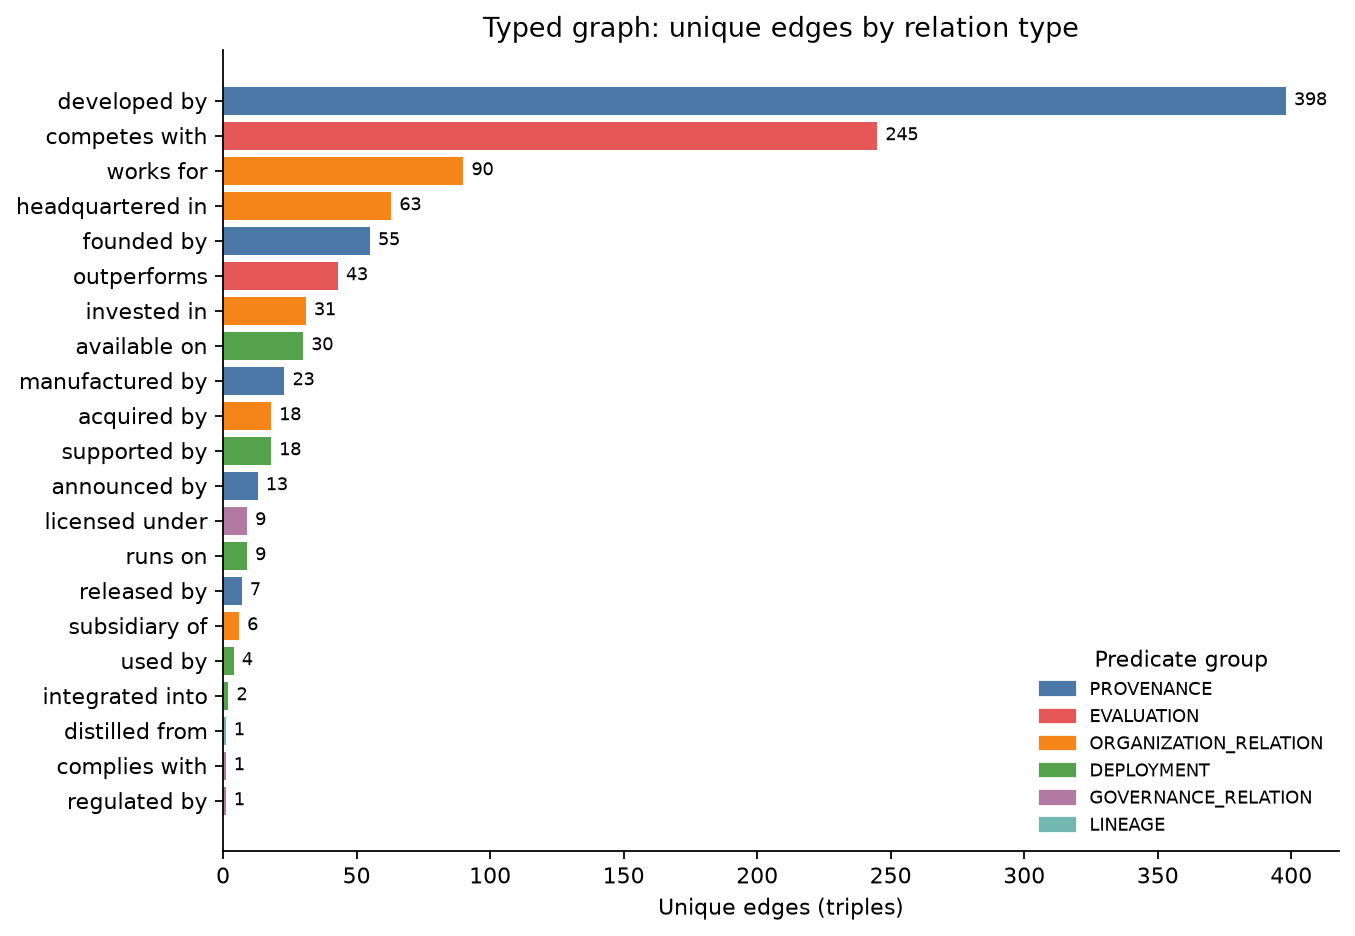

In [14]:
structure = pd.DataFrame({name: graph_summary(graph) for name, graph in
                          [("assertion", assertion_graph), ("typed", typed_graph), ("co-occurrence", cooccurrence_graph)]}).T
typed_undirected = nx.Graph(typed_graph.to_undirected())
structure.loc["typed", "largest_component_nodes"] = len(max(nx.connected_components(typed_undirected), key=len))
structure.loc["co-occurrence", "largest_component_nodes"] = len(max(nx.connected_components(cooccurrence_graph), key=len))
display(structure)

relation_summary = build_relation_type_summary(collapsed)
relation_summary.insert(1, "predicate_group", relation_summary["predicate"].map(PREDICATE_GROUP))
display(relation_summary)

GROUP_COLORS = {"PROVENANCE": "#4C78A8", "EVALUATION": "#E45756", "ORGANIZATION_RELATION": "#F58518",
                "DEPLOYMENT": "#54A24B", "GOVERNANCE_RELATION": "#B279A2", "LINEAGE": "#72B7B2",
                "ATTRIBUTE": "#9D755D", "TRAINING": "#EECA3B"}
COMPACT_COLORS = {"MODEL": "#4C78A8", "ORGANIZATION": "#F58518", "PERSON": "#9D755D", "INFRASTRUCTURE": "#72B7B2",
                  "TECHNICAL_COMPONENT": "#54A24B", "MODEL_ATTRIBUTE": "#B279A2", "EVALUATION_RESOURCE": "#EECA3B",
                  "GOVERNANCE": "#E45756", "LOCATION_OR_GROUP": "#BAB0AC"}
plot_data = relation_summary.sort_values("unique_edges")
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(plot_data["predicate"], plot_data["unique_edges"], color=plot_data["predicate_group"].map(GROUP_COLORS))
for y, value in enumerate(plot_data["unique_edges"]):
    ax.text(value + 3, y, str(value), va="center", fontsize=8)
ax.legend(handles=[Patch(color=c, label=g) for g, c in GROUP_COLORS.items() if g in set(plot_data["predicate_group"])],
          title="Predicate group", frameon=False, loc="lower right", fontsize=8)
ax.set(title="Typed graph: unique edges by relation type", xlabel="Unique edges (triples)", ylabel="")
save_figure(fig, "01_relation_type_counts.png")

### 7.4 Centrality

Three measures describe how central an entity is, with the number of supporting articles as edge weight:

- **weighted degree**: total supporting articles of the entity's edges;
- **PageRank**: high when an entity is connected to other central entities;
- **betweenness**: how often an entity lies on shortest paths between others (sample-based approximation).

PageRank and betweenness of the typed graph are computed on its undirected projection. Direction matters for
individual relations, so they are also analysed separately: for `developed by` (artefact -> organisation) the
in-degree of an organisation is the number of its artefacts in the graph.

In [15]:
typed_metrics = calculate_node_metrics(typed_graph, "typed", "weight", sample_size=1000, seed=SEED)
cooc_metrics = calculate_node_metrics(cooccurrence_graph, "cooccurrence", "document_count", sample_size=500, seed=SEED)
for metrics in (typed_metrics, cooc_metrics):
    metrics["entity_type_compact"] = metrics["entity_id"].map(node_index["entity_type_compact"])

metric_columns = ["canonical_name", "entity_type_compact", "degree", "in_degree", "out_degree",
                  "weighted_degree", "pagerank", "betweenness"]
print("Typed graph: top 15 by PageRank")
display(typed_metrics.head(15)[metric_columns].round(4))
print("Co-occurrence graph: top 15 by PageRank")
display(cooc_metrics.head(15)[[c for c in metric_columns if c in cooc_metrics]].round(4))

relation_metrics = calculate_relation_type_metrics(nodes_kg, collapsed, sample_size=300, seed=SEED)
relation_views = {"developed by": ("in_degree", "organisations with the most artefacts"),
                  "competes with": ("degree", "entities with the most competitors"),
                  "works for": ("in_degree", "organisations with the most named people"),
                  "outperforms": ("out_degree", "models most often described as better than another")}
for predicate, (column, description) in relation_views.items():
    view = relation_metrics[relation_metrics["predicate"] == predicate]
    print(f"[{predicate}] {description} (by {column})")
    display(view.sort_values([column, "weighted_degree"], ascending=False)
            .head(8)[["canonical_name", "entity_type", column, "weighted_degree"]])

Typed graph: top 15 by PageRank


,canonical_name,entity_type_compact,degree,in_degree,out_degree,weighted_degree,pagerank,betweenness
0,NVIDIA,ORGANIZATION,161,146,15,612.0,0.0630,0.2507
1,OpenAI,ORGANIZATION,101,85,16,880.0,0.0550,0.3048
2,Google,ORGANIZATION,113,96,17,663.0,0.0479,0.2159
3,DeepSeek,ORGANIZATION,61,35,26,586.0,0.0351,0.2547
4,Meta,ORGANIZATION,57,43,14,427.0,0.0277,0.0634
5,Anthropic,ORGANIZATION,60,40,20,382.0,0.0250,0.0668
6,Microsoft,ORGANIZATION,51,35,16,256.0,0.0188,0.0584
7,Llama,MODEL,24,10,14,202.0,0.0116,0.0011
8,Amazon,ORGANIZATION,28,14,14,132.0,0.0094,0.0259
9,Nemotron,MODEL,9,1,8,102.0,0.0089,0.0157


Co-occurrence graph: top 15 by PageRank


,canonical_name,entity_type_compact,degree,weighted_degree,pagerank,betweenness
0,NVIDIA,ORGANIZATION,1099,11402.0,0.0319,0.3095
1,DeepSeek,ORGANIZATION,905,12343.0,0.0311,0.1785
2,OpenAI,ORGANIZATION,729,12815.0,0.0303,0.2909
3,Google,ORGANIZATION,802,10917.0,0.0279,0.2157
4,united_states,LOCATION_OR_GROUP,632,9174.0,0.0219,0.1068
5,open_source_model,MODEL_ATTRIBUTE,543,9129.0,0.0214,0.1213
6,Llama,MODEL,611,8206.0,0.0206,0.0947
7,China,LOCATION_OR_GROUP,501,7044.0,0.0166,0.0428
8,Meta,ORGANIZATION,438,6852.0,0.0157,0.0379
9,Anthropic,ORGANIZATION,419,6936.0,0.0155,0.0256


[developed by] organisations with the most artefacts (by in_degree)


...

,canonical_name,entity_type,degree,weighted_degree
69,Google,COMPANY,35,378.0
68,OpenAI,COMPANY,29,471.0
70,DeepSeek,COMPANY,29,332.0
71,Anthropic,COMPANY,26,261.0
73,NVIDIA,COMPANY,21,112.0
72,Meta,COMPANY,19,213.0
74,Microsoft,COMPANY,16,142.0
75,Alibaba,COMPANY,15,99.0


[works for] organisations with the most named people (by in_degree)


,canonical_name,entity_type,in_degree,weighted_degree
948,NVIDIA,COMPANY,10,26.0
949,Meta,COMPANY,6,29.0
950,Microsoft,COMPANY,6,14.0
951,Google,COMPANY,6,9.0
955,OpenAI,COMPANY,3,12.0
953,Anthropic,COMPANY,3,6.0
952,IBM,COMPANY,3,5.0
954,Red Hat,COMPANY,3,3.0


[outperforms] models most often described as better than another (by out_degree)


,canonical_name,entity_type,out_degree,weighted_degree
844,GPT-4o,AI_MODEL,7,22.0
842,Qwen,FOUNDATION_MODEL,5,30.0
845,Kimi,FOUNDATION_MODEL,4,16.0
847,Mistral,FOUNDATION_MODEL,3,13.0
849,GLM,FOUNDATION_MODEL,3,9.0
855,Phi,FOUNDATION_MODEL,3,7.0
843,Llama,FOUNDATION_MODEL,2,28.0
846,Claude,AI_MODEL,1,14.0


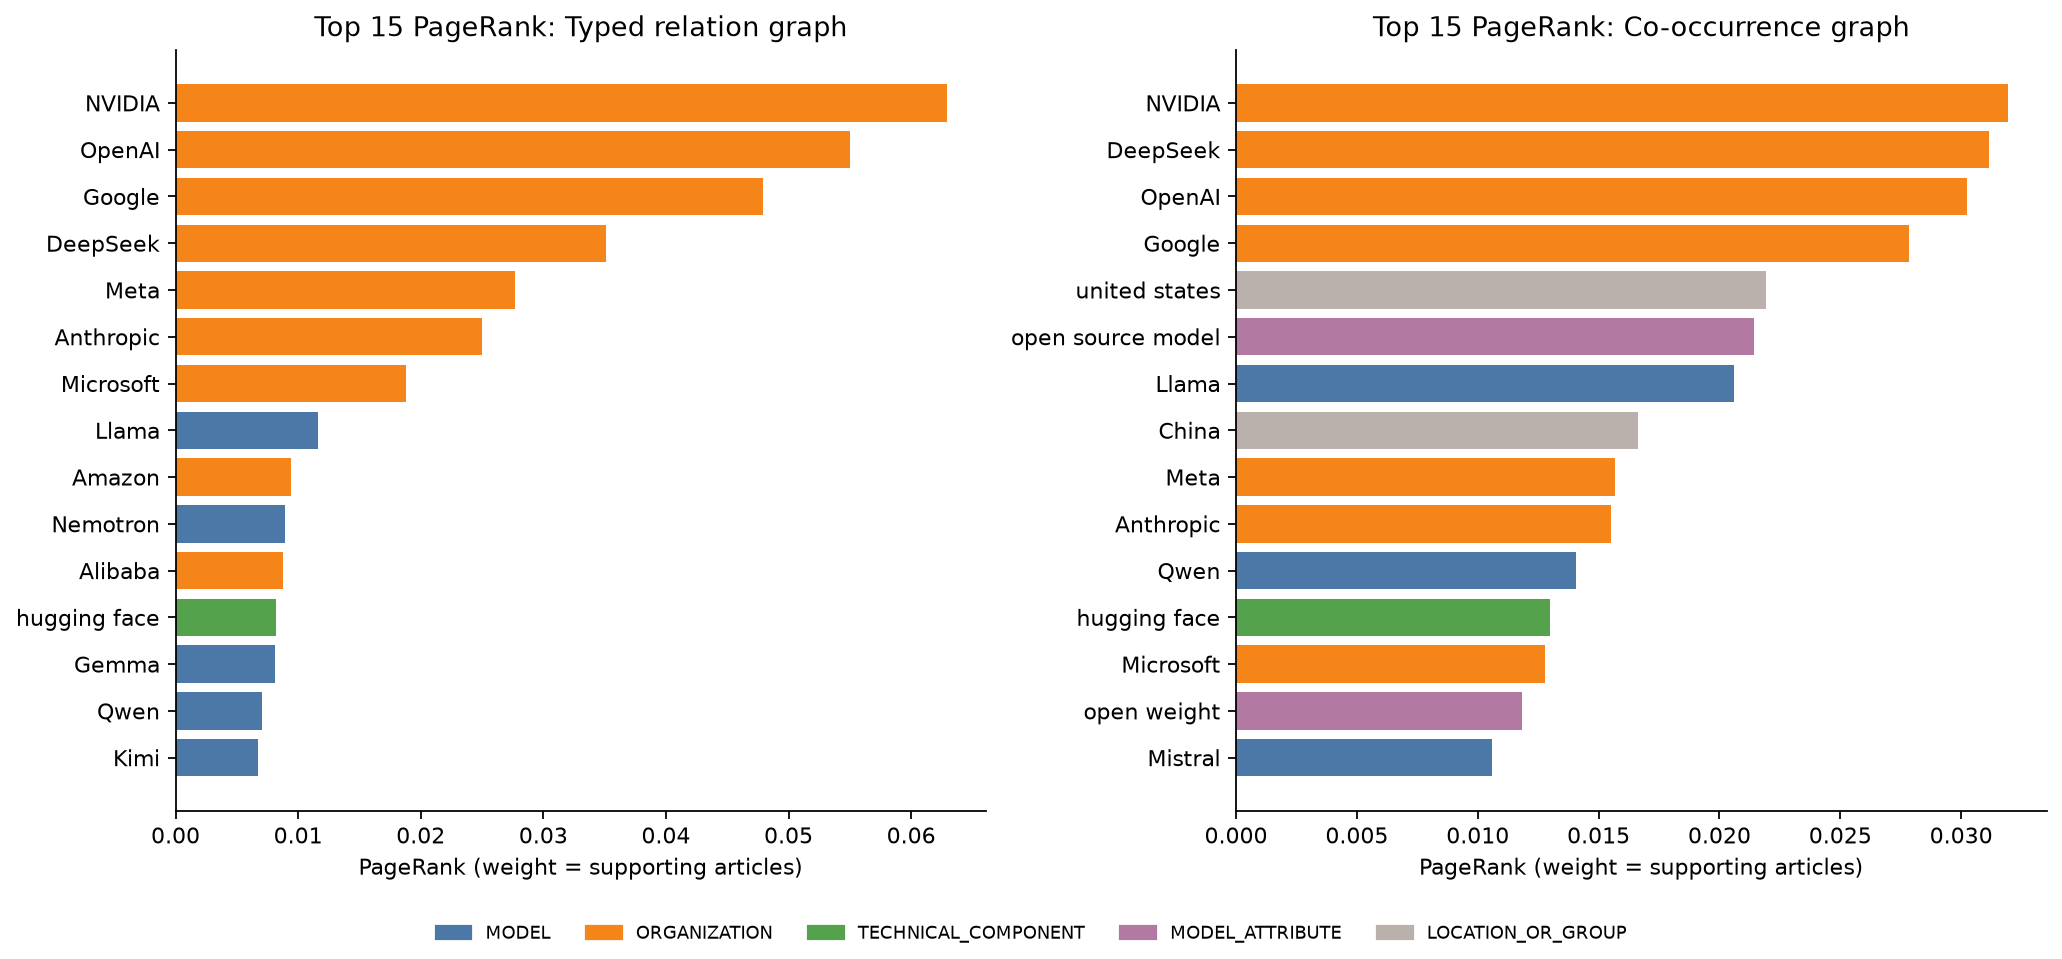


**Interpretation**

- The seven highest-PageRank entities of the typed graph are NVIDIA, OpenAI, Google, DeepSeek, Meta, Anthropic, Microsoft
  (ORGANIZATION). Open model families in the top 15:
  Llama, Nemotron, Gemma, Qwen, Kimi.
- **NVIDIA** has the most artefacts linked by `developed by` (in-degree 83,
  e.g. Nemotron, DGX Spark, NemoClaw, Blackwell architecture): it appears both as a
  hardware supplier and as a model and software developer.
- **OpenAI** has both the highest `competes with` weight (471 supporting articles) and the highest betweenness (0.30) in the typed graph: it connects otherwise separate parts of the graph.
- The co-occurrence ranking also contains context entities (united states, open source model, China, open weight), which reflect the background
  of the reporting (US-China competition, the open vs. closed debate) rather than typed relations.
- 14 of the top-20 entities are shared by both views: the set of central actors is fairly stable, but
  ranks depend on the graph view and thresholds and are not a measure of industry influence.


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, metrics, title in [(axes[0], typed_metrics, "Typed relation graph"), (axes[1], cooc_metrics, "Co-occurrence graph")]:
    top = metrics.head(15).iloc[::-1]
    ax.barh(top["canonical_name"].map(pretty), top["pagerank"], color=top["entity_type_compact"].map(COMPACT_COLORS))
    ax.set(title=f"Top 15 PageRank: {title}", xlabel="PageRank (weight = supporting articles)")
present = set(typed_metrics.head(15)["entity_type_compact"]) | set(cooc_metrics.head(15)["entity_type_compact"])
fig.legend(handles=[Patch(color=COMPACT_COLORS[t], label=t) for t in COMPACT_COLORS if t in present],
           loc="lower center", ncol=len(present), frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.05, 1, 1))
save_figure(fig, "02_pagerank_typed_vs_cooccurrence.png")

labels = node_index["canonical_name"]
developers = relation_metrics[relation_metrics["predicate"] == "developed by"].nlargest(1, "in_degree").iloc[0]
developer_products = collapsed[(collapsed["predicate"] == "developed by") & (collapsed["object_id"] == developers["entity_id"])]
competition = relation_metrics[relation_metrics["predicate"] == "competes with"].nlargest(1, "weighted_degree").iloc[0]
bridge = typed_metrics.nlargest(1, "betweenness").iloc[0]
context = cooc_metrics.head(15)
context = context[context["entity_type_compact"].isin(["LOCATION_OR_GROUP", "MODEL_ATTRIBUTE"])]["canonical_name"].map(pretty)
overlap = set(typed_metrics.head(20)["entity_id"]) & set(cooc_metrics.head(20)["entity_id"])
top_typed = typed_metrics.head(7)
if competition["entity_id"] == bridge["entity_id"]:
    competition_text = (f"**{competition['canonical_name']}** has both the highest `competes with` weight "
                        f"({int(competition['weighted_degree'])} supporting articles) and the highest betweenness "
                        f"({bridge['betweenness']:.2f}) in the typed graph: it connects otherwise separate parts of the graph.")
else:
    competition_text = (f"**{competition['canonical_name']}** has the highest `competes with` weight "
                        f"({int(competition['weighted_degree'])} supporting articles), and **{bridge['canonical_name']}** "
                        f"has the highest betweenness ({bridge['betweenness']:.2f}) in the typed graph.")
display(Markdown(f'''
**Interpretation**

- The seven highest-PageRank entities of the typed graph are {", ".join(top_typed["canonical_name"])}
  ({", ".join(sorted(set(top_typed["entity_type_compact"])))}). Open model families in the top 15:
  {", ".join(typed_metrics.head(15).query("entity_type_compact == 'MODEL'")["canonical_name"])}.
- **{developers["canonical_name"]}** has the most artefacts linked by `developed by` (in-degree {int(developers["in_degree"])},
  e.g. {", ".join(developer_products.nlargest(4, "document_count")["subject_id"].map(labels))}): it appears both as a
  hardware supplier and as a model and software developer.
- {competition_text}
- The co-occurrence ranking also contains context entities ({", ".join(context)}), which reflect the background
  of the reporting (US-China competition, the open vs. closed debate) rather than typed relations.
- {len(overlap)} of the top-20 entities are shared by both views: the set of central actors is fairly stable, but
  ranks depend on the graph view and thresholds and are not a measure of industry influence.
'''))

### 7.5 Clustering and Communities

Groups of entities that are mentioned together show the sub-themes of the open-model discourse. Clustering is
meaningful on the triangle-rich co-occurrence graph and naturally low on the star-shaped typed graph. Communities
are detected with greedy modularity, using the number of shared articles as weight.

In [17]:
clustering_table = pd.DataFrame(
    [("typed (undirected projection)", nx.average_clustering(typed_undirected), np.nan, nx.transitivity(typed_undirected)),
     ("co-occurrence", nx.average_clustering(cooccurrence_graph),
      nx.average_clustering(cooccurrence_graph, weight="document_count"), nx.transitivity(cooccurrence_graph))],
    columns=["view", "average clustering", "weighted average clustering", "transitivity"],
).round(4)
display(clustering_table)

community_members, community_summary = detect_cooccurrence_communities(cooccurrence_graph)
community_sets = [set(group["entity_id"]) for _, group in community_members.groupby("community_id")]
modularity = nx.community.modularity(cooccurrence_graph, community_sets, weight="document_count")
community_summary["top_entities"] = community_summary["top_entities"].map(lambda v: ", ".join(json.loads(v)[:8]))
community_summary["share_of_nodes"] = (community_summary["node_count"] / cooccurrence_graph.number_of_nodes()).round(3)
print(f"{len(community_summary)} communities, modularity {modularity:.3f}")
display(community_summary.head(10))

,view,average clustering,weighted average clustering,transitivity
0,typed (undirected projection),0.0980,NaN,0.0689
1,co-occurrence,0.5409,0.008,0.0776


192 communities, modularity 0.236


,community_id,node_count,edge_count,top_entities,share_of_nodes
0,1,1666,6739,"OpenAI, Google, open_source_model, Llama, Anth...",0.343
1,2,1338,3899,"united_states, DeepSeek, China, NVIDIA, Micros...",0.275
2,3,896,3582,"vllm, Nemotron, Google Cloud, IBM, Dell Techno...",0.184
3,4,124,313,"TrueFoundry, observability, routing, reliabili...",0.026
4,5,97,162,"MLA, Grouped-Query Attention, Multi-Head Atten...",0.020
5,6,44,65,"Facebook, Instagram, WhatsApp, Discord, Messen...",0.009
6,7,29,36,"MLLM, ControlNet, CLIP, T5-XXL, SD3, IP-Adapte...",0.006
7,8,16,32,"Kit, WebGPU, personality, Nico, Michael Knight...",0.003
8,9,16,49,"Arka Venture Labs, Astir VC, Good News Venture...",0.003
9,10,15,27,"Liquid AI, LFMs, Liquid, liquid neural network...",0.003


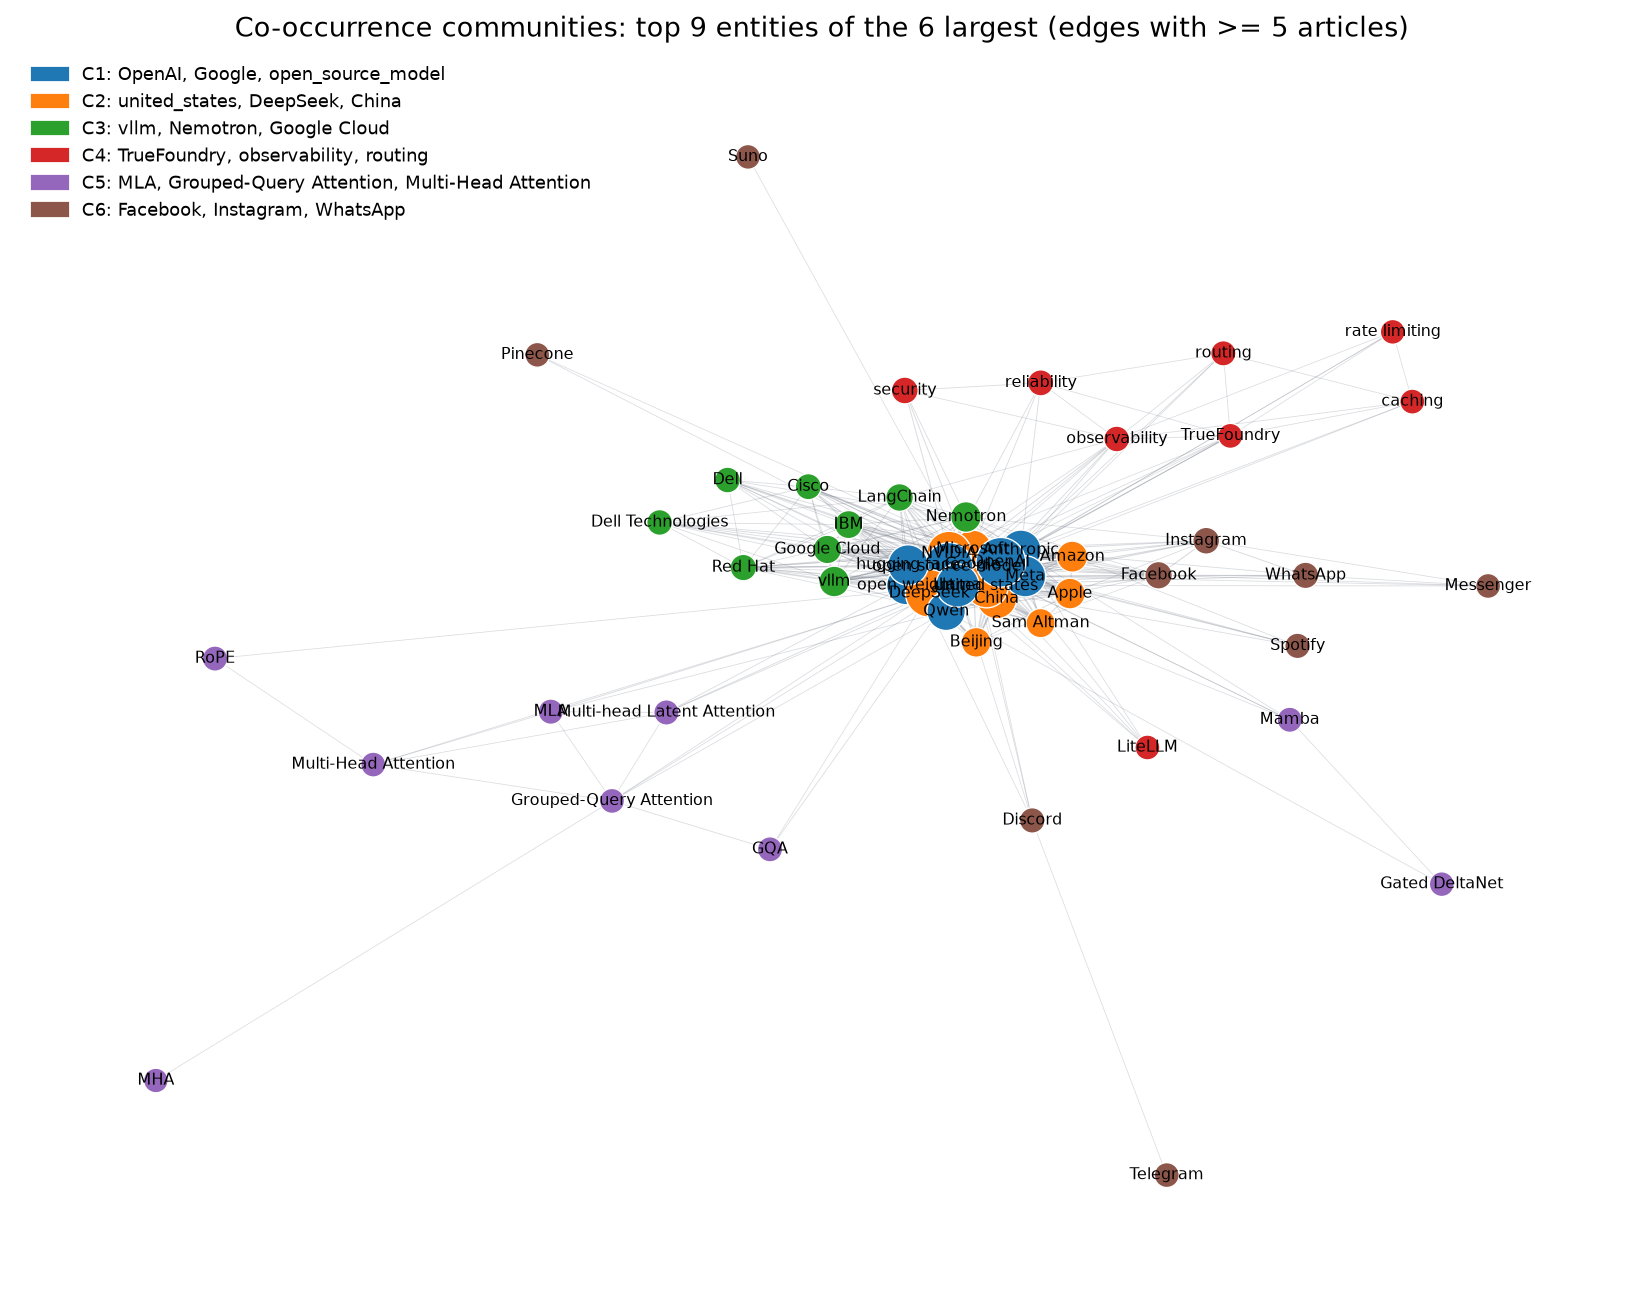


**Interpretation**

- Average clustering is 0.54 in the co-occurrence graph and
  0.10 in the typed graph: co-mentions in one article form triangles,
  typed relations mostly form stars (many models -> one developer).
- Modularity is low (0.24) because the main organisations and models are mentioned across most
  articles. The three largest communities still cover 80% of the nodes
  and read as distinct themes:
  - **C1 (34%)** OpenAI, Google, open source model, Llama, Anthropic, Qwen, Meta, open weight: US frontier labs and the open vs. closed model debate;
  - **C2 (28%)** united states, DeepSeek, China, NVIDIA, Microsoft, Beijing, Apple, Sam Altman: US-China competition after DeepSeek, chips and export controls;
  - **C3 (18%)** vllm, Nemotron, Google Cloud, IBM, Dell Technologies, Cisco, Red Hat, LangChain: enterprise deployment and inference infrastructure.
- Smaller communities are single topics, e.g. TrueFoundry (124 nodes)
  and MLA (97 nodes).
- Community names are interpretations of their top entities.


In [18]:
TOP_COMMUNITIES, NODES_PER_COMMUNITY = 6, 9
top_members = community_members[(community_members["community_id"] <= TOP_COMMUNITIES)
                                & (community_members["rank_in_community"] <= NODES_PER_COMMUNITY)]
draw = cooccurrence_graph.subgraph(top_members["entity_id"]).copy()
draw.remove_edges_from([(a, b) for a, b, d in draw.edges(data=True) if d["document_count"] < DRAW_COOCCURRENCE_DOCUMENTS])
draw.remove_nodes_from(list(nx.isolates(draw)))
community_of = top_members.set_index("entity_id")["community_id"]
palette = plt.get_cmap("tab10")
positions = nx.spring_layout(draw, seed=SEED, weight="document_count", k=2.4 / np.sqrt(max(len(draw), 1)), iterations=500)
fig, ax = plt.subplots(figsize=(13, 10))
max_docs = max(nx.get_edge_attributes(draw, "document_count").values())
nx.draw_networkx_edges(draw, positions, width=[0.3 + 2.5 * d["document_count"] / max_docs for _, _, d in draw.edges(data=True)],
                       alpha=0.25, edge_color="#6B7280", ax=ax)
nx.draw_networkx_nodes(draw, positions, ax=ax, linewidths=0.6, edgecolors="white",
                       node_color=[palette(community_of[n] - 1) for n in draw],
                       node_size=[120 + 0.6 * draw.nodes[n]["document_count"] for n in draw])
nx.draw_networkx_labels(draw, positions, labels={n: pretty(draw.nodes[n]["label"]) for n in draw}, font_size=7, ax=ax)
legend_labels = community_summary.set_index("community_id")["top_entities"]
ax.legend(handles=[Patch(color=palette(c - 1), label=f"C{c}: " + ", ".join(legend_labels[c].split(", ")[:3]))
                   for c in range(1, TOP_COMMUNITIES + 1)], loc="upper left", frameon=False, fontsize=8)
ax.set_title(f"Co-occurrence communities: top {NODES_PER_COMMUNITY} entities of the {TOP_COMMUNITIES} largest "
             f"(edges with >= {DRAW_COOCCURRENCE_DOCUMENTS} articles)")
ax.axis("off")
save_figure(fig, "03_cooccurrence_communities.png")

c = community_summary.set_index("community_id").assign(top_entities=lambda d: d["top_entities"].map(pretty))
display(Markdown(f'''
**Interpretation**

- Average clustering is {clustering_table.loc[1, "average clustering"]:.2f} in the co-occurrence graph and
  {clustering_table.loc[0, "average clustering"]:.2f} in the typed graph: co-mentions in one article form triangles,
  typed relations mostly form stars (many models -> one developer).
- Modularity is low ({modularity:.2f}) because the main organisations and models are mentioned across most
  articles. The three largest communities still cover {c.loc[[1, 2, 3], "share_of_nodes"].sum():.0%} of the nodes
  and read as distinct themes:
  - **C1 ({c.loc[1, "share_of_nodes"]:.0%})** {c.loc[1, "top_entities"]}: US frontier labs and the open vs. closed model debate;
  - **C2 ({c.loc[2, "share_of_nodes"]:.0%})** {c.loc[2, "top_entities"]}: US-China competition after DeepSeek, chips and export controls;
  - **C3 ({c.loc[3, "share_of_nodes"]:.0%})** {c.loc[3, "top_entities"]}: enterprise deployment and inference infrastructure.
- Smaller communities are single topics, e.g. {c.loc[4, "top_entities"].split(", ")[0]} ({c.loc[4, "node_count"]} nodes)
  and {c.loc[5, "top_entities"].split(", ")[0]} ({c.loc[5, "node_count"]} nodes).
- Community names are interpretations of their top entities.
'''))

### 7.6 Temporal Analysis

All dates are article publication dates, so the results describe when relations were *reported* in the corpus.

1. relation evidence sentences per quarter, by predicate group;
2. typed relations first observed per quarter;
3. share of Open Models articles mentioning each top model family per quarter (`nodes_quarterly`);
4. relations first observed in 2026 (candidates for emerging relationships);
5. entities whose share of relation evidence changed most between the first and second year.

The first quarter (2024Q3) only contains September and the last (2026Q3) only July and August.

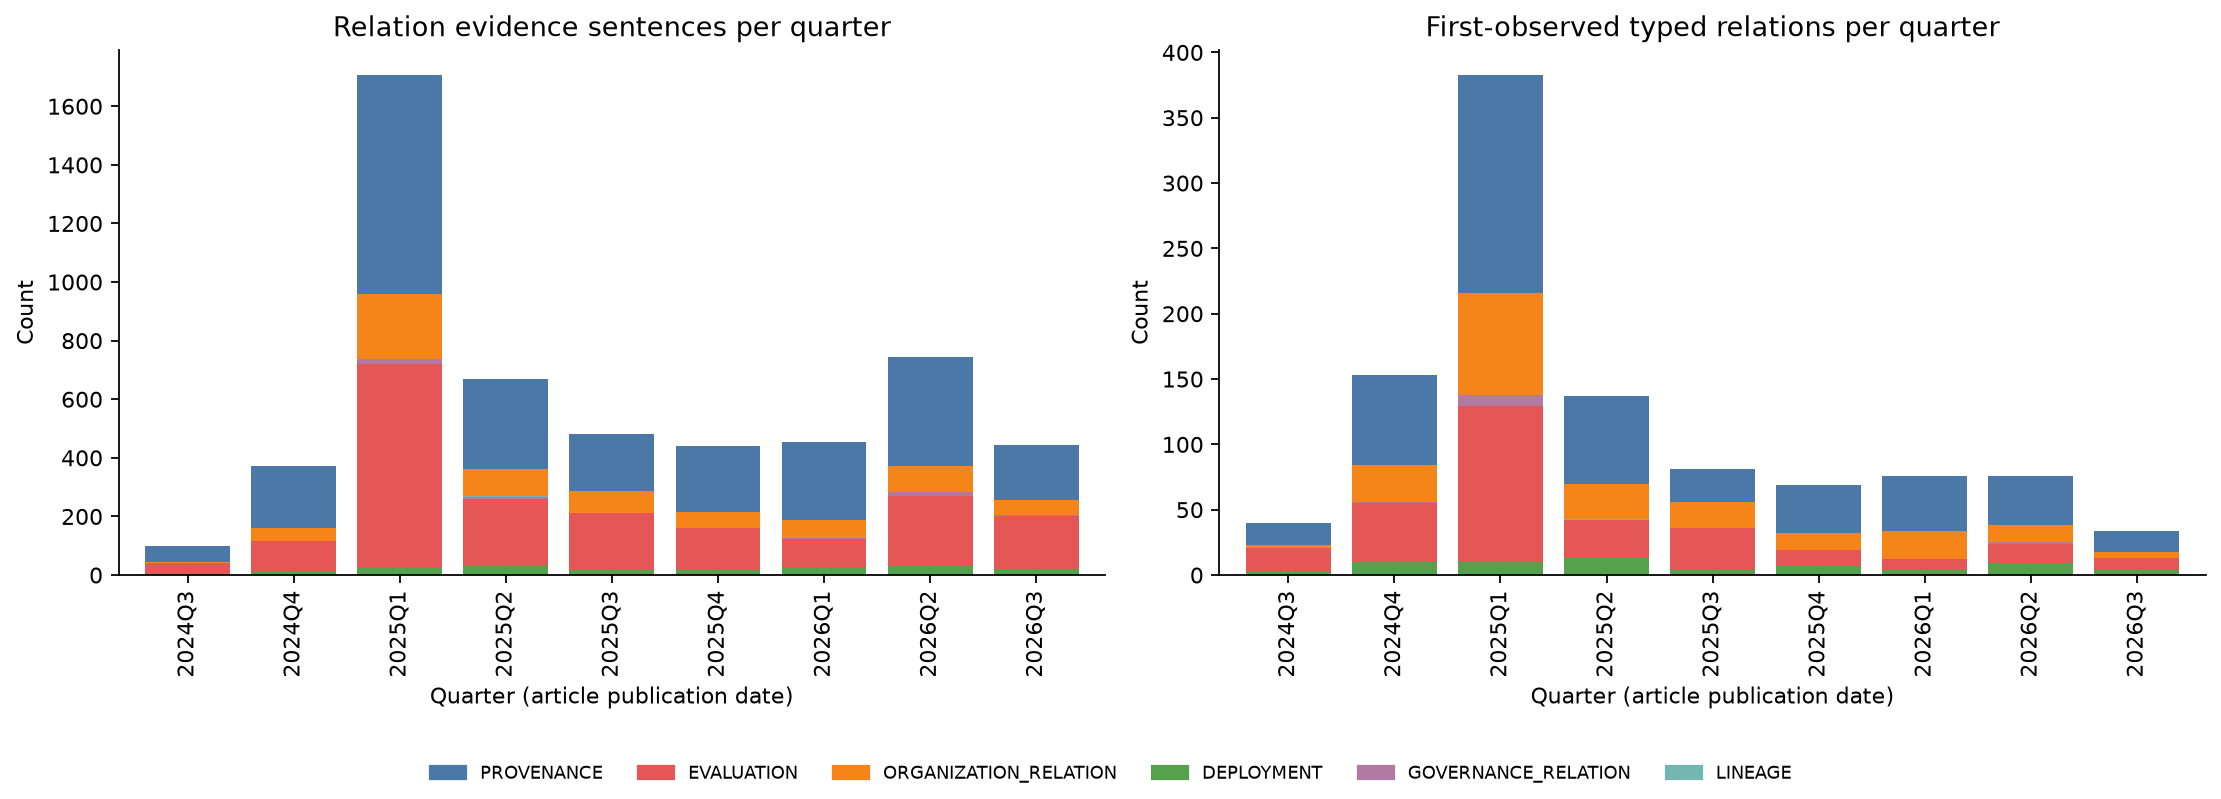

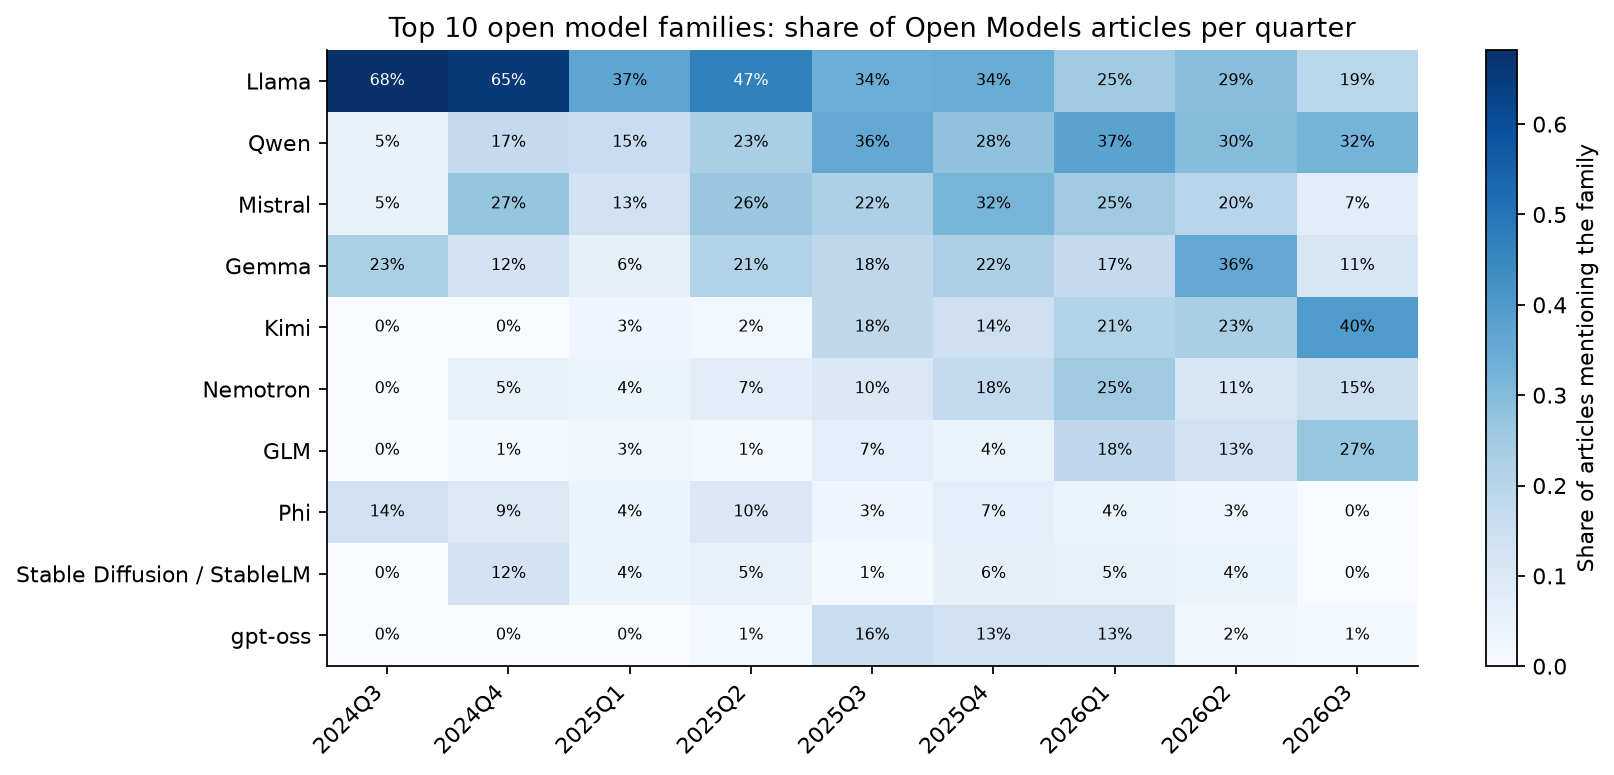

quarter,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2,2026Q3
articles,22,104,349,156,103,90,99,179,108


In [19]:
dated = assertions[assertions["extraction_method"] == "glirel"].copy()
dated["quarter"] = pd.to_datetime(dated["published_at"]).dt.to_period("Q").astype(str)
dated["predicate_group"] = dated["predicate"].map(PREDICATE_GROUP)
quarterly_assertions = dated.pivot_table(index="quarter", columns="predicate_group", values="relation_id",
                                         aggfunc="count", fill_value=0)
new_edges = collapsed[collapsed["first_seen"].notna()].copy()
new_edges["quarter"] = pd.to_datetime(new_edges["first_seen"]).dt.to_period("Q").astype(str)
quarterly_new_edges = new_edges.pivot_table(index="quarter", columns="predicate_group", values="predicate",
                                            aggfunc="count", fill_value=0)

mentions = pd.read_csv(EXTRACTION_DIR / "entity_mentions.csv", usecols=["doc_id", "quarter"])
articles_per_quarter = mentions.drop_duplicates("doc_id")["quarter"].value_counts().sort_index()
families = nodes_kg[nodes_kg["is_open_model_family"]].set_index("entity_id")["canonical_name"]
family_quarterly = nodes_quarterly.assign(entity_id=nodes_quarterly["entity_id"].map(id_map))
family_quarterly = (family_quarterly[family_quarterly["entity_id"].isin(families.index)]
                    .groupby(["entity_id", "quarter"])["n_docs"].sum().unstack(fill_value=0))
family_share = family_quarterly.div(articles_per_quarter.reindex(family_quarterly.columns), axis=1)
family_share = family_share.loc[family_quarterly.sum(axis=1).nlargest(10).index].rename(index=families)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, table, title in [(axes[0], quarterly_assertions, "Relation evidence sentences per quarter"),
                         (axes[1], quarterly_new_edges, "First-observed typed relations per quarter")]:
    table.plot(ax=ax, kind="bar", stacked=True, width=0.8, legend=False,
               color=[GROUP_COLORS.get(c, "#BAB0AC") for c in table.columns])
    ax.set(title=title, xlabel="Quarter (article publication date)", ylabel="Count")
handles = [Patch(color=GROUP_COLORS[g], label=g) for g in GROUP_COLORS if g in set(quarterly_assertions.columns)]
fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(fig, "04_quarterly_relations.png")

fig, ax = plt.subplots(figsize=(11, 5))
image = ax.imshow(family_share.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(family_share.shape[1]), family_share.columns, rotation=45, ha="right")
ax.set_yticks(range(family_share.shape[0]), family_share.index)
for (i, j), value in np.ndenumerate(family_share.values):
    ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontsize=7,
            color="white" if value > family_share.values.max() * 0.6 else "black")
fig.colorbar(image, ax=ax, label="Share of articles mentioning the family")
ax.set_title("Top 10 open model families: share of Open Models articles per quarter")
save_figure(fig, "05_family_quarterly_share.png")
display(articles_per_quarter.rename("articles").to_frame().T)

In [20]:
emerging = collapsed[(collapsed["first_seen"].fillna("") >= "2026-01-01") & (collapsed["document_count"] >= 2)].copy()
emerging["edge"] = (emerging["subject_id"].map(labels) + " -> " + emerging["predicate"] + " -> "
                    + emerging["object_id"].map(labels))
print(f"Relations first observed in 2026 and supported by >= 2 articles: {len(emerging)}")
display(emerging.sort_values(["document_count", "first_seen"], ascending=[False, True])
        .head(15)[["edge", "predicate_group", "document_count", "first_seen", "last_seen", "review_status"]])

def period_share(start, end):
    rows = dated[(dated["published_at"] >= start) & (dated["published_at"] <= end)]
    long = pd.concat([rows[["subject_id", "document_id"]].rename(columns={"subject_id": "entity_id"}),
                      rows[["object_id", "document_id"]].rename(columns={"object_id": "entity_id"})])
    return long.drop_duplicates().groupby("entity_id")["document_id"].nunique() / rows["document_id"].nunique()

shares = pd.DataFrame({name: period_share(*span) for name, span in PERIODS.items()}).fillna(0)
p1, p2 = shares.columns
shares["change_pp"] = (shares[p2] - shares[p1]) * 100
shares["canonical_name"] = shares.index.map(labels)
shares["entity_type_compact"] = shares.index.map(node_index["entity_type_compact"])
print("Share of relation-evidence articles per entity: change from P1 to P2 (percentage points)")
display(pd.concat([shares.nlargest(10, "change_pp"), shares.nsmallest(5, "change_pp")])
        [["canonical_name", "entity_type_compact", p1, p2, "change_pp"]].round(3))

peak_quarter = articles_per_quarter.idxmax()
first_q, last_q = family_share.columns[0], family_share.columns[-1]
fs = family_share
risers = shares.nlargest(5, "change_pp")
fallers = shares.nsmallest(3, "change_pp")
display(Markdown(f'''
**Interpretation**

- **{peak_quarter} dominates**: it has the most articles ({articles_per_quarter[peak_quarter]}) and
  {quarterly_assertions.sum(axis=1)[peak_quarter]:,} relation evidence sentences (median quarter:
  {int(quarterly_assertions.sum(axis=1).median()):,}), the period after the DeepSeek-R1 release. Comparisons over time
  therefore use shares rather than counts.
- **Model families**: the share of articles mentioning Llama moved from {fs.loc["Llama", first_q]:.0%} ({first_q}) to
  {fs.loc["Llama", last_q]:.0%} ({last_q}), while Qwen moved from {fs.loc["Qwen", first_q]:.0%} to {fs.loc["Qwen", last_q]:.0%},
  Kimi from {fs.loc["Kimi", first_q]:.0%} to {fs.loc["Kimi", last_q]:.0%} and GLM from {fs.loc["GLM", first_q]:.0%} to
  {fs.loc["GLM", last_q]:.0%}. Nemotron peaked at {fs.loc["Nemotron"].max():.0%} in {fs.loc["Nemotron"].idxmax()}.
- **Relation evidence, P1 -> P2**: largest increases for
  {", ".join(f"{r.canonical_name} ({r.change_pp:+.1f} pp)" for r in risers.itertuples())};
  largest decreases for {", ".join(f"{r.canonical_name} ({r.change_pp:+.1f} pp)" for r in fallers.itertuples())}.
- **Relations first observed in 2026** ({len(emerging)} with >= 2 articles) are mostly new products and their
  developers, e.g. {", ".join(emerging[emerging["predicate_group"] == "PROVENANCE"].nlargest(4, "document_count")["edge"])}.
'''))

Relations first observed in 2026 and supported by >= 2 articles: 125


,edge,predicate_group,document_count,first_seen,last_seen,review_status
634,NemoClaw -> developed by -> NVIDIA,PROVENANCE,9,2026-03-11,2026-08-11,unreviewed
15,Latent Space -> acquired by -> AINews,ORGANIZATION_RELATION,8,2026-03-25,2026-05-28,unreviewed
456,Muse Spark -> developed by -> Meta,PROVENANCE,7,2026-04-08,2026-07-24,unreviewed
84,GLM -> competes with -> Anthropic,EVALUATION,5,2026-06-25,2026-08-19,unreviewed
764,Anthropic -> headquartered in -> China,ORGANIZATION_RELATION,4,2026-02-04,2026-08-07,unreviewed
565,AI Gateway -> developed by -> TrueFoundry,PROVENANCE,4,2026-03-02,2026-06-04,unreviewed
551,OpenClaw -> developed by -> NVIDIA,PROVENANCE,4,2026-03-11,2026-04-30,unreviewed
684,hugging_face -> developed by -> Google DeepMind,PROVENANCE,4,2026-03-11,2026-06-10,unreviewed
553,OpenShell -> developed by -> NVIDIA,PROVENANCE,4,2026-03-16,2026-07-27,unreviewed
460,Mythos -> developed by -> Anthropic,PROVENANCE,4,2026-04-04,2026-06-12,unreviewed


Share of relation-evidence articles per entity: change from P1 to P2 (percentage points)


,canonical_name,entity_type_compact,P1 (2024-09 to 2025-08),P2 (2025-09 to 2026-08),change_pp
entity_id,,,,,
org:anthropic,Anthropic,ORGANIZATION,0.142,0.291,14.913
model:nemotron,Nemotron,MODEL,0.044,0.143,9.914
model:kimi,Kimi,MODEL,0.027,0.102,7.433
org:nvidia,NVIDIA,ORGANIZATION,0.213,0.280,6.711
model:gemma,Gemma,MODEL,0.075,0.126,5.169
model:glm,GLM,MODEL,0.007,0.058,5.041
org:moonshot_ai,MoonShot AI,ORGANIZATION,0.015,0.060,4.587
org:google,Google,ORGANIZATION,0.321,0.357,3.656
hardware:dgx_spark,DGX Spark,INFRASTRUCTURE,0.007,0.033,2.568



**Interpretation**

- **2025Q1 dominates**: it has the most articles (349) and
  1,708 relation evidence sentences (median quarter:
  453), the period after the DeepSeek-R1 release. Comparisons over time
  therefore use shares rather than counts.
- **Model families**: the share of articles mentioning Llama moved from 68% (2024Q3) to
  19% (2026Q3), while Qwen moved from 5% to 32%,
  Kimi from 0% to 40% and GLM from 0% to
  27%. Nemotron peaked at 25% in 2026Q1.
- **Relation evidence, P1 -> P2**: largest increases for
  Anthropic (+14.9 pp), Nemotron (+9.9 pp), Kimi (+7.4 pp), NVIDIA (+6.7 pp), Gemma (+5.2 pp);
  largest decreases for DeepSeek (-27.0 pp), Meta (-13.0 pp), Llama (-9.8 pp).
- **Relations first observed in 2026** (125 with >= 2 articles) are mostly new products and their
  developers, e.g. NemoClaw -> developed by -> NVIDIA, Muse Spark -> developed by -> Meta, GPT-5.5 -> developed by -> OpenAI, Mythos -> developed by -> Anthropic.


### 7.7 Graph Visualisations

The full graph is too dense for one figure, so each figure answers one question. Node colour is the compact entity
type and edge colour the predicate group; thresholds are stated in the titles.

1. **Core typed graph**: relations among the entities with the highest PageRank.
2. **Open model families -> developer**: article support of each family-developer edge, split into lexicon
   relations confirmed by articles, lexicon-only relations and article-only relations.
3. **Competition and benchmark claims**: `competes with` (no direction) and `outperforms` (arrow).

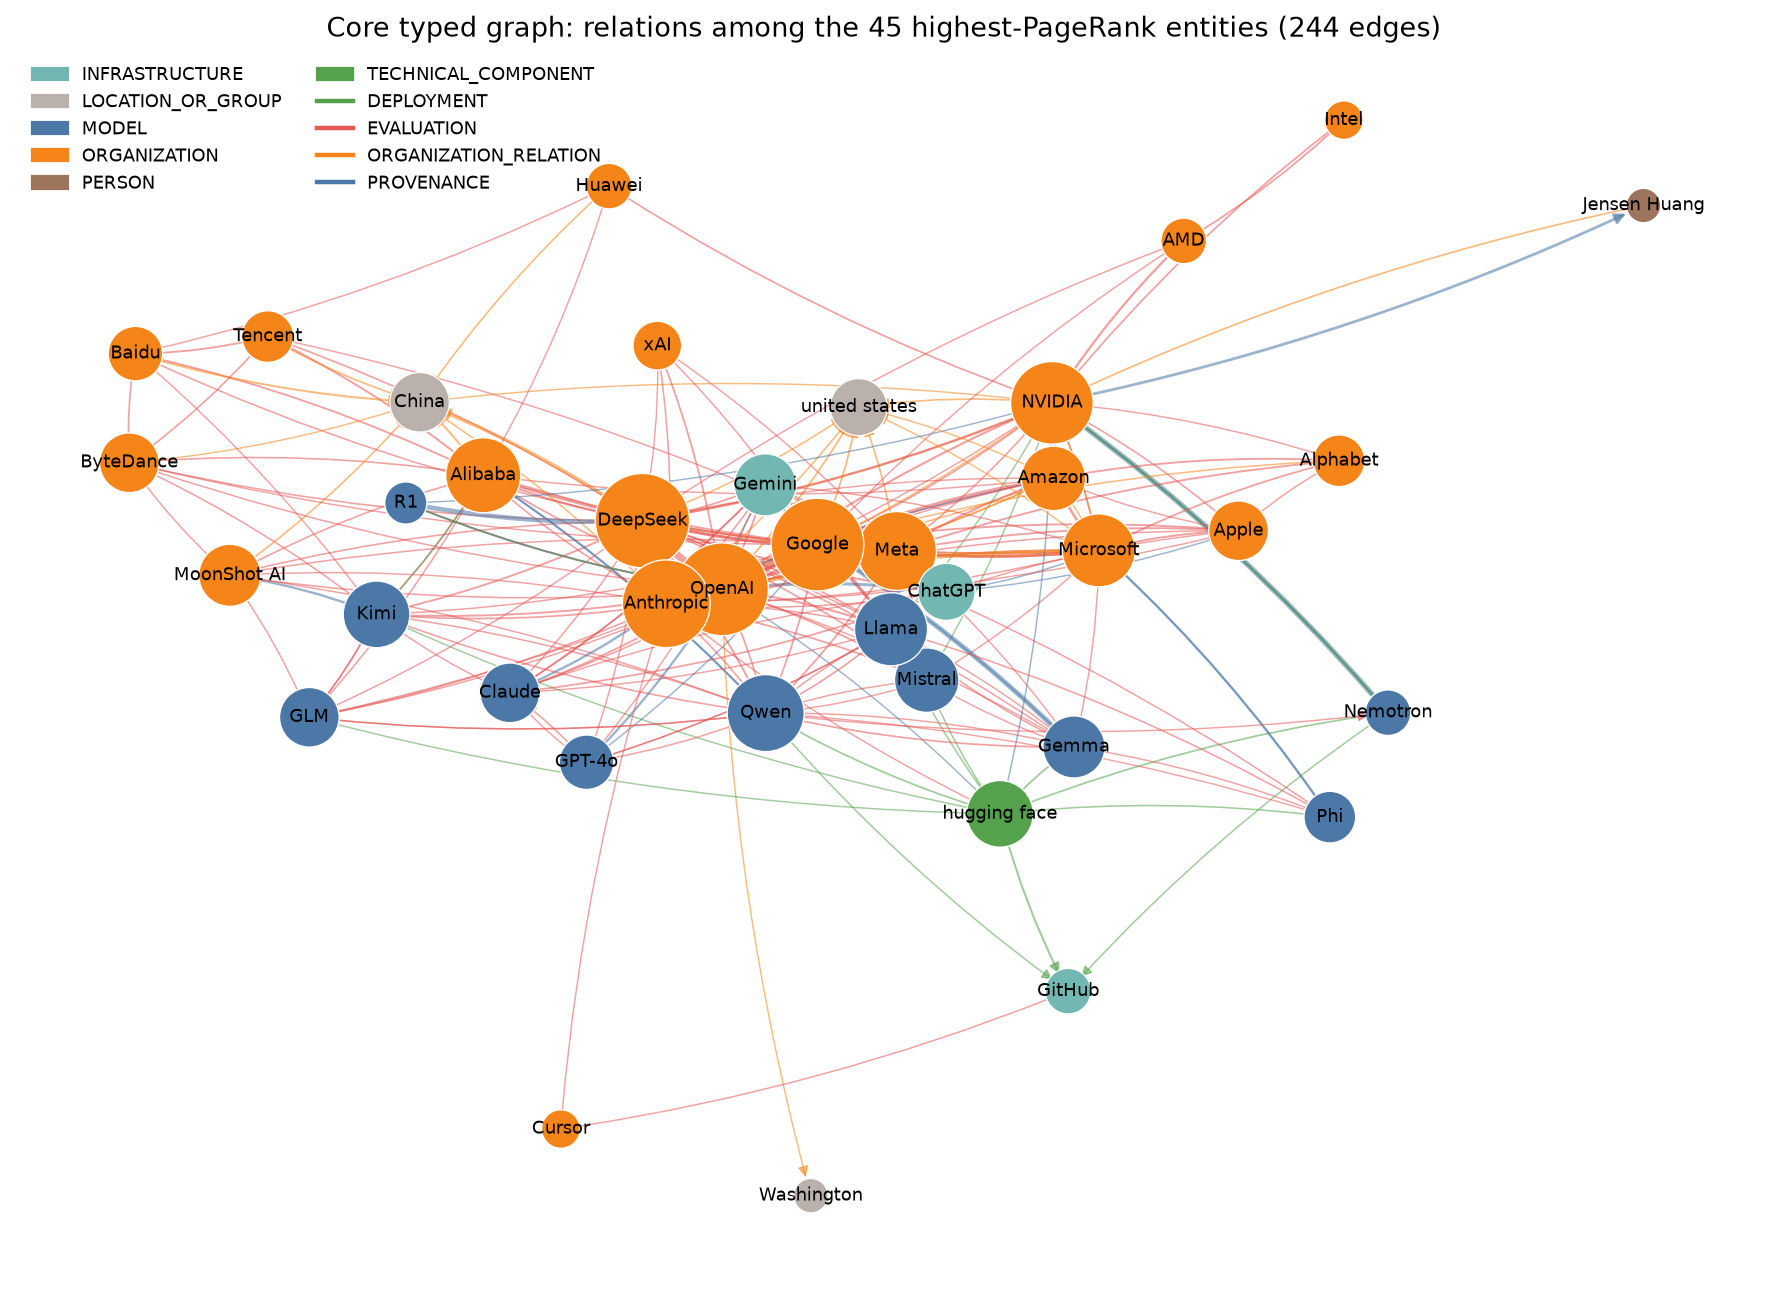

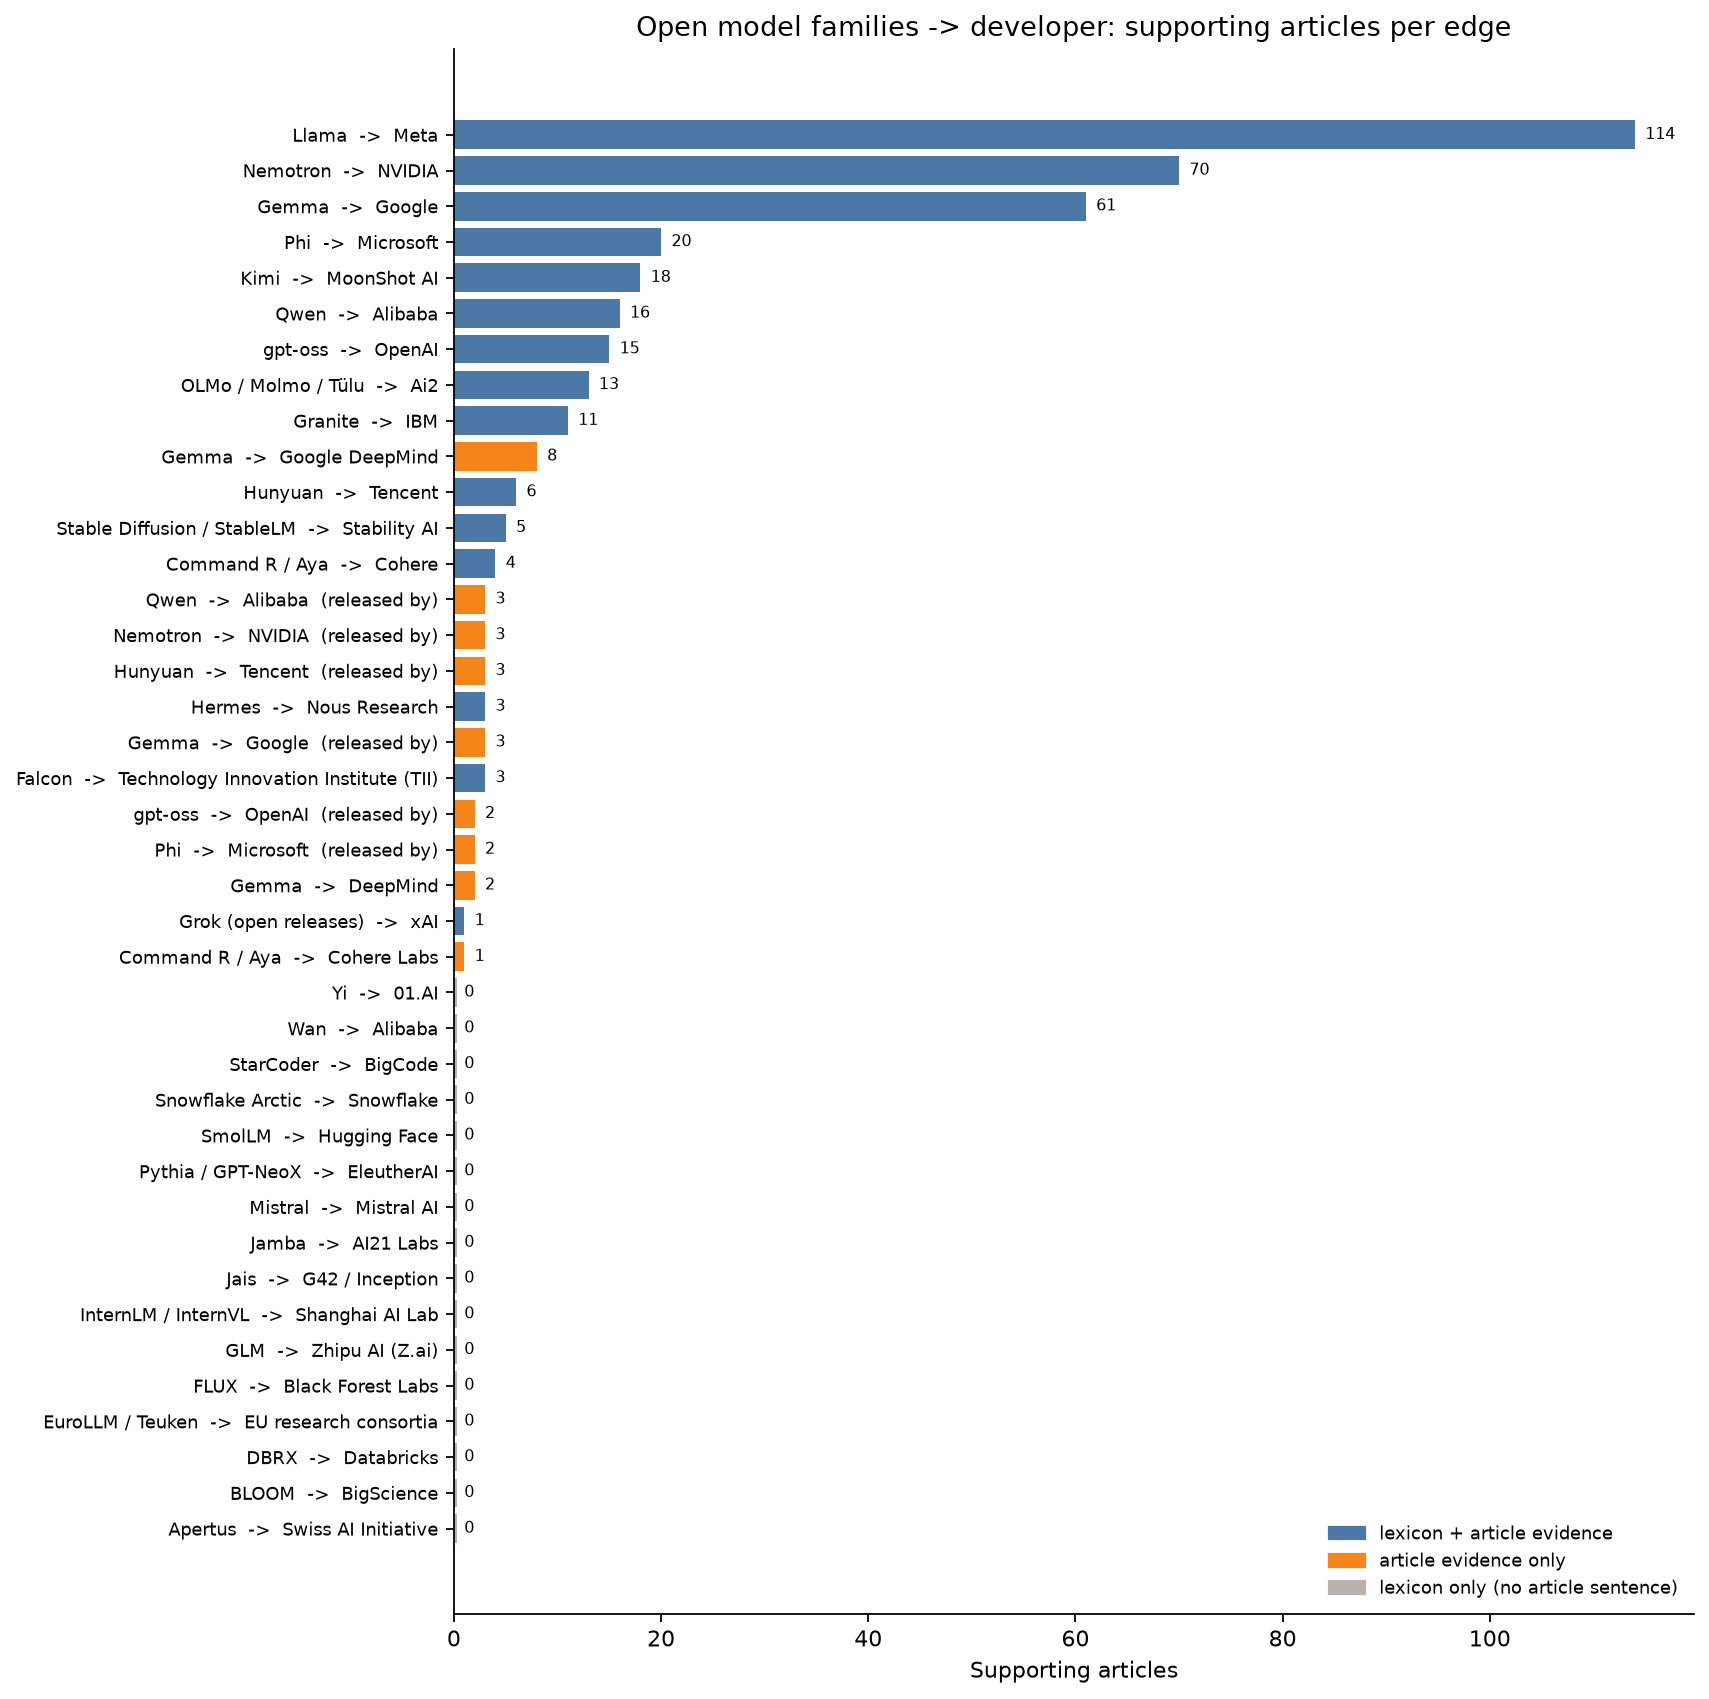

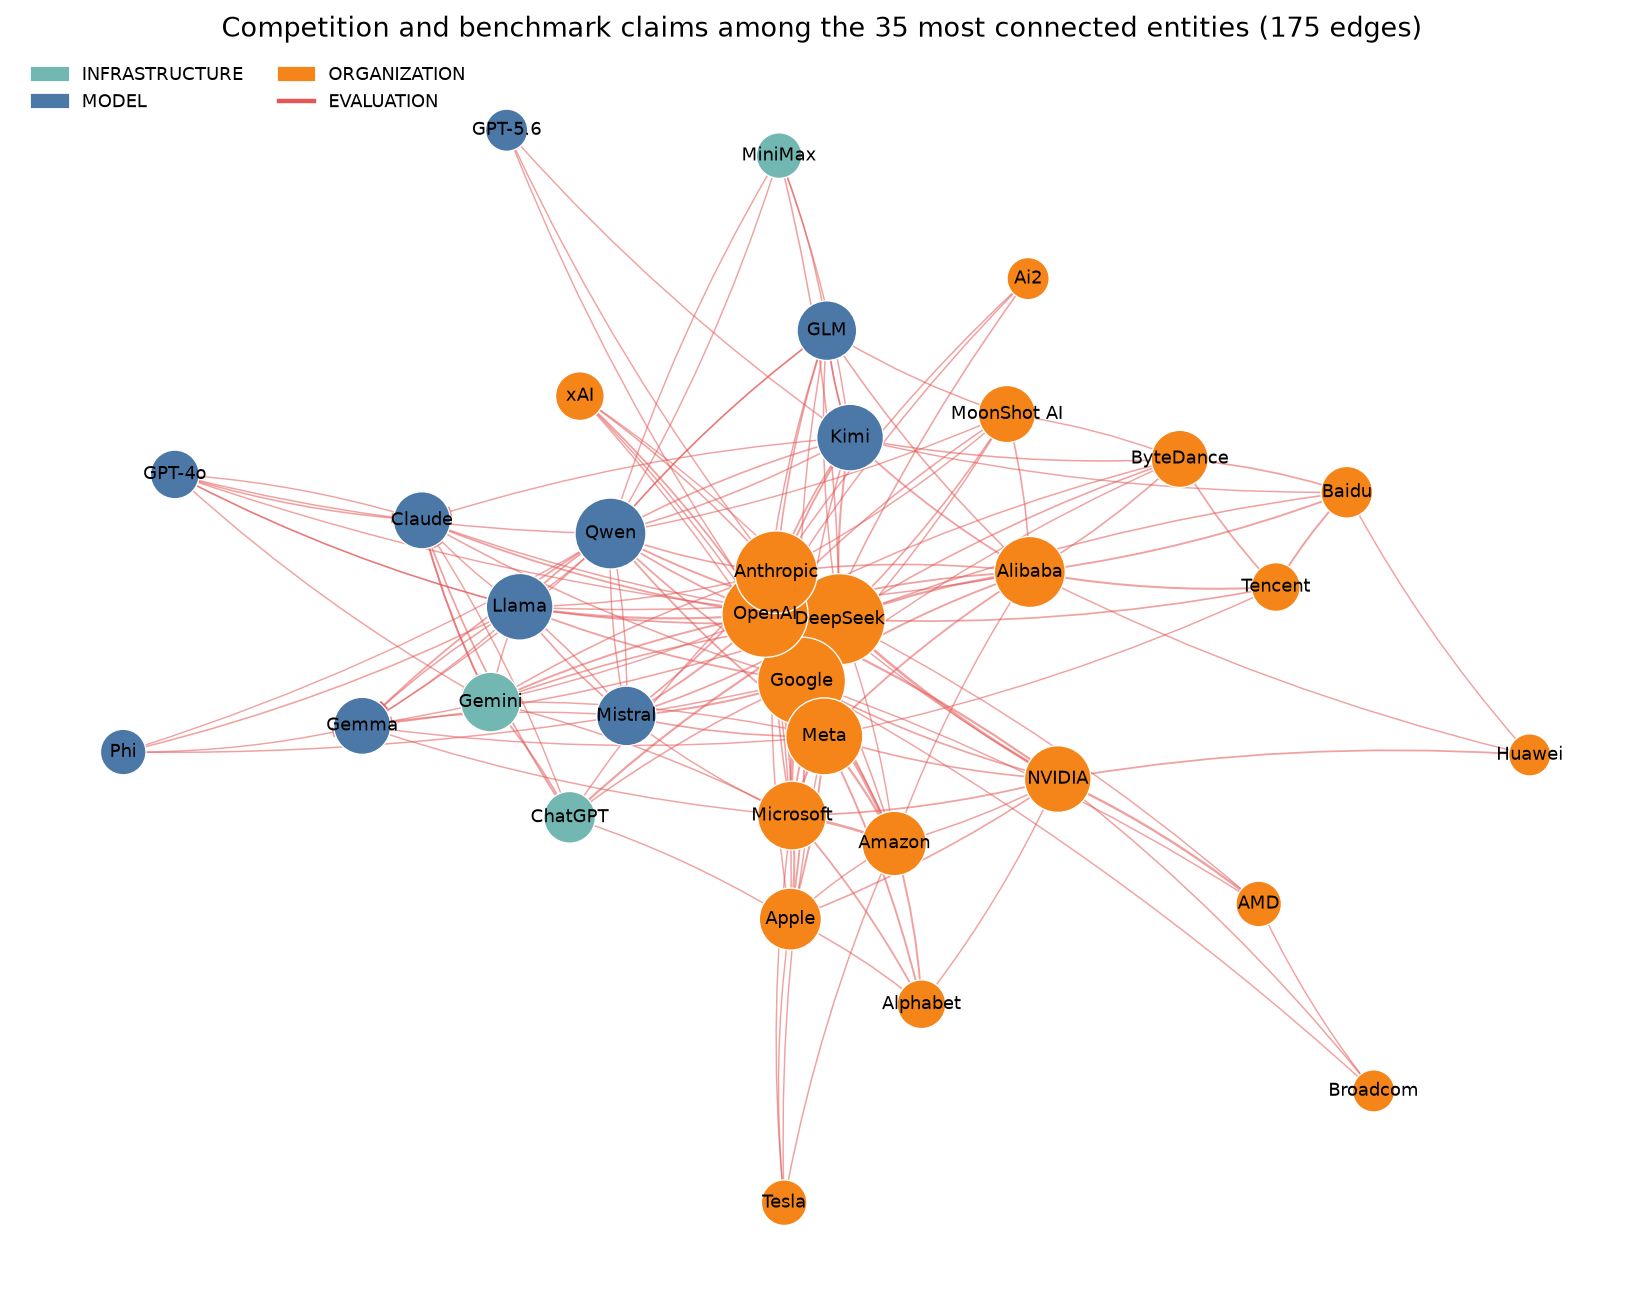

In [21]:
def draw_typed_subgraph(edges, title, filename, max_labels=40, figsize=(14, 10)):
    graph = nx.MultiDiGraph()
    for row in edges.itertuples(index=False):
        for entity_id in (row.subject_id, row.object_id):
            graph.add_node(entity_id, label=labels[entity_id], compact=node_index.loc[entity_id, "entity_type_compact"])
        graph.add_edge(row.subject_id, row.object_id, key=row.predicate, group=row.predicate_group,
                       weight=row.weight, directed=row.directed, sources=row.sources)
    simple = nx.Graph(graph.to_undirected())
    positions = nx.spring_layout(simple, seed=SEED, k=1.6 / np.sqrt(len(simple)), iterations=400)
    fig, ax = plt.subplots(figsize=figsize)
    max_weight = max(d["weight"] for _, _, d in graph.edges(data=True))
    for source, target, data in graph.edges(data=True):
        nx.draw_networkx_edges(graph, positions, edgelist=[(source, target)], ax=ax,
                               width=0.6 + 3.0 * data["weight"] / max_weight,
                               edge_color=GROUP_COLORS.get(data["group"], "#6B7280"), alpha=0.55,
                               arrows=True, arrowstyle="-|>" if data["directed"] else "-", arrowsize=10,
                               connectionstyle="arc3,rad=0.06", node_size=300)
    degree = dict(simple.degree())
    nx.draw_networkx_nodes(graph, positions, ax=ax, linewidths=0.6, edgecolors="white",
                           node_color=[COMPACT_COLORS[graph.nodes[n]["compact"]] for n in graph],
                           node_size=[180 + 60 * degree[n] for n in graph])
    shown = sorted(graph, key=lambda n: -degree[n])[:max_labels]
    nx.draw_networkx_labels(graph, positions, labels={n: pretty(graph.nodes[n]["label"]) for n in shown},
                            font_size=8, ax=ax)
    groups = sorted({d["group"] for _, _, d in graph.edges(data=True)})
    types = sorted({graph.nodes[n]["compact"] for n in graph})
    handles = ([Patch(color=COMPACT_COLORS[t], label=t) for t in types]
               + [Line2D([0], [0], color=GROUP_COLORS[g], lw=2, label=g) for g in groups])
    ax.legend(handles=handles, loc="upper left", frameon=False, fontsize=8, ncol=2)
    ax.set_title(title)
    ax.axis("off")
    save_figure(fig, filename)

core_ids = set(typed_metrics.head(45)["entity_id"])
core_edges = collapsed[collapsed["subject_id"].isin(core_ids) & collapsed["object_id"].isin(core_ids)]
draw_typed_subgraph(core_edges, f"Core typed graph: relations among the 45 highest-PageRank entities ({len(core_edges)} edges)",
                    "06_core_typed_graph.png")

family_ids = set(nodes_kg.loc[nodes_kg["is_open_model_family"], "entity_id"])
family_edges = collapsed[collapsed["subject_id"].isin(family_ids) & collapsed["predicate"].isin(["developed by", "released by"])]
family_plot = family_edges.assign(
    pair=(family_edges["subject_id"].map(labels).map(pretty) + "  ->  " + family_edges["object_id"].map(labels).map(pretty)
          + np.where(family_edges["predicate"].eq("released by"), "  (released by)", "")),
    evidence=np.select(
        [family_edges["sources"].str.contains("glirel") & family_edges["sources"].str.contains("wp1_lexicon"),
         family_edges["sources"].str.contains("glirel")],
        ["lexicon + article evidence", "article evidence only"], default="lexicon only (no article sentence)"),
).sort_values(["document_count", "pair"]).reset_index(drop=True)
EVIDENCE_COLORS = {"lexicon + article evidence": "#4C78A8", "article evidence only": "#F58518",
                   "lexicon only (no article sentence)": "#BAB0AC"}
fig, ax = plt.subplots(figsize=(10, 0.28 * len(family_plot) + 1.5))
ax.barh(family_plot["pair"], family_plot["document_count"].clip(lower=0.3), color=family_plot["evidence"].map(EVIDENCE_COLORS))
for y, value in enumerate(family_plot["document_count"]):
    ax.text(value + 1, y, str(int(value)), va="center", fontsize=7)
ax.legend(handles=[Patch(color=c, label=l) for l, c in EVIDENCE_COLORS.items()], loc="lower right", frameon=False, fontsize=8)
ax.set(title="Open model families -> developer: supporting articles per edge", xlabel="Supporting articles", ylabel="")
ax.tick_params(axis="y", labelsize=8)
save_figure(fig, "07_family_developer_edges.png")

compete = collapsed[collapsed["predicate"].isin(["competes with", "outperforms"])]
compete_ids = set(pd.concat([compete["subject_id"], compete["object_id"]]).value_counts().head(35).index)
compete = compete[compete["subject_id"].isin(compete_ids) & compete["object_id"].isin(compete_ids)]
draw_typed_subgraph(compete, f"Competition and benchmark claims among the 35 most connected entities ({len(compete)} edges)",
                    "08_competition_graph.png", figsize=(13, 10))

## 8. Key Insights

This section brings together the trends and topics of the corpus (8.1), the findings of the knowledge graph (8.2)
and a consistency check between the two (8.3).

### 8.1 Open Models Trends and Topics

> **TODO (integration):** move the key insights of the data and topic analysis notebook (Section 12) here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

### 8.2 Knowledge Graph Findings with Evidence

Each finding is based on a graph pattern, and the table attaches the number of supporting articles and the
highest-scoring evidence sentence with its publication date, so that every claim can be traced back to the
articles.

In [22]:
def evidence_example(subject_id, predicate, object_id):
    rows = dated[(dated["subject_id"] == subject_id) & (dated["predicate"] == predicate) & (dated["object_id"] == object_id)]
    rows = rows.sort_values("rule_score", ascending=False).drop_duplicates("document_id").head(1)
    return " ".join(f"[{r.published_at}] {' '.join(str(r.evidence_text).split())[:220]}" for r in rows.itertuples(index=False))

findings = []
for row in relation_metrics[relation_metrics["predicate"] == "developed by"].nlargest(5, "in_degree").itertuples(index=False):
    products = collapsed[(collapsed["predicate"] == "developed by") & (collapsed["object_id"] == row.entity_id)]
    top = products.nlargest(4, "document_count")
    example = next((evidence_example(s, "developed by", row.entity_id) for s in top["subject_id"]
                    if evidence_example(s, "developed by", row.entity_id)), "")
    findings.append({"finding": "developer hub", "entity or relation": row.canonical_name,
                     "measure": f"developed by in-degree {int(row.in_degree)}", "articles": int(products["document_count"].sum()),
                     "detail": ", ".join(top["subject_id"].map(labels)), "evidence": example})
for row in collapsed[collapsed["predicate"] == "competes with"].nlargest(5, "document_count").itertuples(index=False):
    findings.append({"finding": "strong competition", "entity or relation": f"{labels[row.subject_id]} -- {labels[row.object_id]}",
                     "measure": "supporting articles", "articles": int(row.document_count),
                     "detail": f"{row.first_seen} to {row.last_seen}",
                     "evidence": evidence_example(row.subject_id, row.predicate, row.object_id)})
for row in emerging.nlargest(5, "document_count").itertuples(index=False):
    findings.append({"finding": "first observed in 2026", "entity or relation": row.edge, "measure": "first seen",
                     "articles": int(row.document_count), "detail": row.first_seen,
                     "evidence": evidence_example(row.subject_id, row.predicate, row.object_id)})
findings = pd.DataFrame(findings)
with pd.option_context("display.max_colwidth", 170):
    display(findings)

hub = findings[findings["finding"] == "developer hub"].iloc[0]
rivals = findings[findings["finding"] == "strong competition"].head(3)
deepseek = shares.loc["org:deepseek"] if "org:deepseek" in shares.index else None
deepseek_text = (f"DeepSeek's share of relation evidence fell from {deepseek[p1]:.0%} in P1 to {deepseek[p2]:.0%} in P2."
                 if deepseek is not None else "")
display(Markdown(f'''
**Findings**

1. **Open-model attention shifted from Llama to Chinese model families and NVIDIA's Nemotron.** Articles mentioning
   Llama fell from {fs.loc["Llama", first_q]:.0%} to {fs.loc["Llama", last_q]:.0%} of the Open Models articles per quarter,
   while Qwen ({fs.loc["Qwen", last_q]:.0%}), Kimi ({fs.loc["Kimi", last_q]:.0%}) and GLM ({fs.loc["GLM", last_q]:.0%}) rose
   (Section 7.6). Mentions show visibility in the media, not usage or quality.
2. **{hub["entity or relation"]} is the most connected developer** ({hub["measure"]}; e.g. {hub["detail"]}). Its links
   span hardware, models and agent software, and several of its products are among the relations first observed
   in 2026 (Sections 7.4 and 7.6).
3. **Competition is reported around a few frontier players**: the strongest `competes with` pairs are
   {"; ".join(f"{r['entity or relation']} ({r['articles']} articles)" for _, r in rivals.iterrows())} (Section 7.7).
4. **One quarter shapes the whole graph.** {peak_quarter} contains the most articles and relation evidence.
   {deepseek_text} Centrality over the whole period is therefore strongly influenced by this quarter.

`outperforms` relations are not used for findings: they are often extracted from sentences in which a third model
outperforms both entities (e.g. "it outperforms Qwen 2.5, Gemma 3 and Llama 3").
'''))

,finding,entity or relation,measure,articles,detail,evidence
0,developer hub,NVIDIA,developed by in-degree 83,314,"Nemotron, DGX Spark, NemoClaw, Blackwell architecture",[2025-08-14] NVIDIA-Nemotron-Nano-12B-v2-Base is a large language model (LLM) developed by NVIDIA that is designed as a completion model for a given piece of text.
1,developer hub,Google,developed by in-degree 61,239,"Gemma, Gemini, ML Pathways, TPUs","[2026-06-10] Developed by Google DeepMind, DiffusionGemma undergoes the same rigorous safety evaluations as our proprietary Gemini models."
2,developer hub,OpenAI,developed by in-degree 51,333,"ChatGPT, GPT-5, o1, GPT-4",[2025-03-19] OpenAI has developed ChatGPT into one of the prominent alternatives to Le Chat.
3,developer hub,Anthropic,developed by in-degree 22,83,"Claude, MCP, Sonnet, Claude Code","[2026-03-25] Claude can now use your computer (Activity: 2106): Claude, an AI developed by Anthropic, is now capable of using your computer to perform tasks via Claud..."
4,developer hub,DeepSeek,developed by in-degree 17,149,"R1, R1 model, Chinese AI, V3","[2025-01-27] The model was developed by the Chinese AI startup DeepSeek, which claims that R1 matches or even surpasses OpenAI’s ChatGPT o1 on multiple key benchmarks..."
5,strong competition,DeepSeek -- OpenAI,supporting articles,103,2024-12-17 to 2026-08-11,[2024-12-17] DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.
6,strong competition,Anthropic -- OpenAI,supporting articles,97,2024-09-25 to 2026-08-27,"[2026-01-15] The company is a public benefit corporation, like OpenAI and competitor Anthropic, which created Claude."
7,strong competition,Google -- OpenAI,supporting articles,80,2024-09-25 to 2026-08-19,"[2025-01-30] This development intensifies the AI-generated media race, placing Google in competition with OpenAI’s Sora and other video synthesis models emerging in t..."
8,strong competition,Anthropic -- Google,supporting articles,51,2024-09-25 to 2026-08-19,"[2026-07-09] Muse Spark 1.1 changes that equation by allowing developers to call Meta’s own hosted infrastructure via the new Meta Model API, putting the company in d..."
9,strong competition,Google -- Meta,supporting articles,42,2024-12-04 to 2026-07-24,"[2025-05-01] With this rollout, Meta enters direct competition with Google Assistant and ChatGPT, aiming to become the go-to AI assistant for both casual and professi..."



**Findings**

1. **Open-model attention shifted from Llama to Chinese model families and NVIDIA's Nemotron.** Articles mentioning
   Llama fell from 68% to 19% of the Open Models articles per quarter,
   while Qwen (32%), Kimi (40%) and GLM (27%) rose
   (Section 7.6). Mentions show visibility in the media, not usage or quality.
2. **NVIDIA is the most connected developer** (developed by in-degree 83; e.g. Nemotron, DGX Spark, NemoClaw, Blackwell architecture). Its links
   span hardware, models and agent software, and several of its products are among the relations first observed
   in 2026 (Sections 7.4 and 7.6).
3. **Competition is reported around a few frontier players**: the strongest `competes with` pairs are
   DeepSeek -- OpenAI (103 articles); Anthropic -- OpenAI (97 articles); Google -- OpenAI (80 articles) (Section 7.7).
4. **One quarter shapes the whole graph.** 2025Q1 contains the most articles and relation evidence.
   DeepSeek's share of relation evidence fell from 39% in P1 to 12% in P2. Centrality over the whole period is therefore strongly influenced by this quarter.

`outperforms` relations are not used for findings: they are often extracted from sentences in which a third model
outperforms both entities (e.g. "it outperforms Qwen 2.5, Gemma 3 and Llama 3").


### 8.3 Consistency of Lexicon Trends and Knowledge-Graph Trends

The model-family trend of the exploratory analysis (lexicon matches per 1,000 AI articles, all articles) and the
family share in the knowledge graph (share of Open Models articles that mention the family as an entity) are
measured on different article sets with different methods. If both show the same direction over time, the
knowledge graph reflects the corpus trends rather than extraction artefacts.

In [23]:
wp1_family = pd.read_csv(WP1_FAMILY_TREND_PATH)
wp1_family["quarter"] = pd.PeriodIndex(wp1_family["key"], freq="M").asfreq("Q").astype(str)
wp1_quarterly = wp1_family.drop(columns="key").groupby("quarter").mean()

consistency = []
for family in family_share.index:
    if family not in wp1_quarterly.columns:
        continue
    graph_trend = family_share.loc[family]
    lexicon_trend = wp1_quarterly[family].reindex(graph_trend.index)
    consistency.append({
        "family": family,
        "graph share first / last quarter": f"{graph_trend.iloc[0]:.0%} / {graph_trend.iloc[-1]:.0%}",
        "lexicon per 1,000 first / last quarter": f"{lexicon_trend.iloc[0]:.1f} / {lexicon_trend.iloc[-1]:.1f}",
        "same direction": np.sign(graph_trend.iloc[-1] - graph_trend.iloc[0]) == np.sign(lexicon_trend.iloc[-1] - lexicon_trend.iloc[0]),
        "Spearman correlation": round(graph_trend.corr(lexicon_trend, method="spearman"), 2),
    })
consistency = pd.DataFrame(consistency)
display(consistency)
same_direction = consistency[consistency["same direction"]]
correlated = consistency[consistency["Spearman correlation"] >= 0.5]
shift = ["Llama", "Qwen", "Kimi", "GLM"]
shift_text = ("The shift from Llama towards Qwen, Kimi and GLM (Section 8.2) appears in both measurements."
              if set(shift) <= set(same_direction["family"]) else
              "The two measurements disagree for some of the families behind the shift described in Section 8.2.")
display(Markdown(f'''
{len(same_direction)} of {len(consistency)} families change in the same direction between the first and the last quarter
in both measurements, and {len(correlated)} have a Spearman correlation of at least 0.5 between the quarterly trends
({", ".join(correlated["family"])}). {shift_text} Lower correlations come from quarter-to-quarter fluctuations, which
differ because the two measures use different article sets.
'''))

,family,graph share first / last quarter,"lexicon per 1,000 first / last quarter",same direction,Spearman correlation
0,Llama,68% / 19%,44.1 / 15.0,True,0.83
1,Qwen,5% / 32%,3.1 / 20.9,True,0.37
2,Mistral,5% / 7%,10.5 / 8.5,False,0.43
3,Gemma,23% / 11%,9.4 / 10.6,False,0.58
4,Kimi,0% / 40%,0.0 / 19.0,True,1.00
5,Nemotron,0% / 15%,0.0 / 9.4,True,0.83
6,GLM,0% / 27%,0.0 / 12.7,True,0.98
7,Phi,14% / 0%,6.3 / 0.0,True,0.72
8,Stable Diffusion / StableLM,0% / 0%,4.2 / 1.3,False,0.43
9,gpt-oss,0% / 1%,0.0 / 1.6,True,0.89



7 of 10 families change in the same direction between the first and the last quarter
in both measurements, and 7 have a Spearman correlation of at least 0.5 between the quarterly trends
(Llama, Gemma, Kimi, Nemotron, GLM, Phi, gpt-oss). The shift from Llama towards Qwen, Kimi and GLM (Section 8.2) appears in both measurements. Lower correlations come from quarter-to-quarter fluctuations, which
differ because the two measures use different article sets.


### 8.4 Summary

> **TODO (integration):** move a short summary of the most important insights from 8.1–8.3 (5–6 bullet points) here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

## 9. Storage and Reuse for Stage 3

*Contributor: Jihyeon Choung*

The graph, its schema and a data dictionary are stored so that the graph-enhanced RAG system of Stage 3 can load
them, and the retrieval path from a question to evidence sentences is checked.

### 9.1 Export and Re-load Check

The graph is stored in formats that Stage 3 and external tools can read:

- **Parquet** (canonical tables) and **CSV** (for inspection);
- **GraphML** (Gephi, Cytoscape; list attributes stored as JSON strings) and **node-link JSON** (NetworkX);
- `graph_schema.json`, `DATA_DICTIONARY.md` and a run manifest with input hashes;
- the correction tables, so that every excluded or merged item can be inspected.

The saved graphs are loaded again and compared with the graphs in memory.

In [24]:
alias_names = nodes.set_index("entity_id")["entity"]
nodes_kg["aliases"] = [
    json.dumps(sorted({alias_names.get(i, "") for i in merged_ids.split(" | ")} - {name, ""}), ensure_ascii=False)
    for merged_ids, name in zip(nodes_kg["merged_ids"], nodes_kg["canonical_name"])
]
graph_node_ids = set(typed_graph) | set(cooccurrence_graph) | set(assertion_graph)
nodes_out = (nodes_kg[nodes_kg["entity_id"].isin(graph_node_ids)]
             .merge(typed_metrics[["entity_id", "pagerank", "betweenness", "weighted_degree"]]
                    .rename(columns=lambda c: c if c == "entity_id" else f"typed_{c}"), on="entity_id", how="left")
             .merge(cooc_metrics[["entity_id", "pagerank", "betweenness", "clustering"]]
                    .rename(columns=lambda c: c if c == "entity_id" else f"cooc_{c}"), on="entity_id", how="left")
             .merge(community_members[["entity_id", "community_id"]], on="entity_id", how="left"))

tables = {
    "nodes": nodes_out,
    "typed_edges_assertions": assertions,
    "typed_edges_collapsed": collapsed,
    "cooccurrence_edges": cooccurrence_edges,
    "node_metrics": pd.concat([typed_metrics, cooc_metrics], ignore_index=True),
    "relation_type_metrics": relation_metrics,
    "relation_type_summary": relation_summary,
    "node_communities": community_members,
    "community_summary": community_summary,
    "quarterly_relation_assertions": quarterly_assertions.reset_index(),
    "quarterly_new_typed_edges": quarterly_new_edges.reset_index(),
    "family_quarterly_share": family_share.reset_index(names="family"),
    "emerging_relations_2026": emerging,
    "entity_period_share": shares.reset_index(names="entity_id"),
    "findings": findings,
}
for name, table in tables.items():
    table.to_parquet(OUTPUT_DIR / f"{name}.parquet", index=False)
    table.to_csv(OUTPUT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

correction_tables = {
    "relations_all_tiers": relations,
    "evidence_status": ev.drop(columns=["sentence_key"]),
    "nodes_corrected": nodes_corrected,
    "name_variants": name_variants,
    "alias_map": pd.DataFrame(ALIAS_MAP, columns=["from_id", "to_id", "note"]),
    "node_overrides": pd.DataFrame(NODE_OVERRIDES, columns=["entity_id", "entity", "entity_type", "note"]),
    "developer_equivalents": pd.DataFrame([(d, e) for d, es in DEVELOPER_EQUIVALENTS.items() for e in es],
                                          columns=["lexicon_developer_id", "accepted_id"]),
    "generic_nodes": nodes_corrected[nodes_corrected["is_generic"]][["entity_id", "entity", "entity_type", "mentions"]],
}
for name, table in correction_tables.items():
    table.to_csv(OUTPUT_DIR / "correction" / f"{name}.csv", index=False, encoding="utf-8-sig")

def graphml_safe(graph):
    safe = graph.copy()
    for _, data in safe.nodes(data=True):
        data.update({k: scalar(v) for k, v in data.items()})
    edge_data = safe.edges(keys=True, data=True) if safe.is_multigraph() else safe.edges(data=True)
    for *_, data in edge_data:
        data.update({k: scalar(v) for k, v in data.items()})
    return safe

graphs = {"assertion": assertion_graph, "typed": typed_graph, "cooccurrence": cooccurrence_graph}
for name, graph in graphs.items():
    nx.write_graphml(graphml_safe(graph), OUTPUT_DIR / f"{name}_graph.graphml")
    (OUTPUT_DIR / f"{name}_graph.json").write_text(
        json.dumps(nx.node_link_data(graphml_safe(graph), edges="edges"), ensure_ascii=False), encoding="utf-8")

summary = {
    "schema_version": schema_version, "status": GRAPH_STATUS,
    "created_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "graphs": {name: graph_summary(graph) for name, graph in graphs.items()},
    "relation_types": int(collapsed["predicate"].nunique()),
    "tiers": collapsed["tier"].value_counts().to_dict(),
    "review": {"labelled_rows": n_reviewed, "true": int(review_counts["TRUE"]), "false": int(review_counts["FALSE"]),
               "ambiguous": int(review_counts["AMBIGUOUS"]),
               "precision": None if np.isnan(review_precision) else round(float(review_precision), 4)},
    "cooccurrence_minimum_articles": MIN_COOCCURRENCE_DOCUMENTS,
    "communities": int(len(community_summary)), "modularity": round(float(modularity), 4),
}
sha256 = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
manifest = {**summary,
            "inputs": {str(p.relative_to(ROOT) if p.is_relative_to(ROOT) else p): sha256(p) for p in
                       [EXTRACTION_DIR / f for f in EXTRACTION_FILES] + [LEXICON_PATH, REVIEW_PATH, COMPACT_SCHEMA_PATH]},
            "versions": {"python": sys.version.split()[0], "networkx": nx.__version__, "pandas": pd.__version__}}
for directory in [OUTPUT_DIR, ARTIFACT_DIR]:
    (directory / "graph_schema.json").write_text(json.dumps(graph_schema, ensure_ascii=False, indent=2), encoding="utf-8")
    (directory / "graph_summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
(OUTPUT_DIR / "run_manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
for name in ["typed_edges_collapsed", "relation_type_summary", "community_summary", "findings"]:
    tables[name].to_csv(ARTIFACT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")

reloaded = {
    "typed_graph.graphml": ("typed", nx.read_graphml(OUTPUT_DIR / "typed_graph.graphml")),
    "typed_graph.json": ("typed", nx.node_link_graph(json.loads((OUTPUT_DIR / "typed_graph.json").read_text(encoding="utf-8")), edges="edges")),
    "cooccurrence_graph.graphml": ("cooccurrence", nx.read_graphml(OUTPUT_DIR / "cooccurrence_graph.graphml")),
    "assertion_graph.json": ("assertion", nx.node_link_graph(json.loads((OUTPUT_DIR / "assertion_graph.json").read_text(encoding="utf-8")), edges="edges")),
}
reload_check = pd.DataFrame([
    (name, g.number_of_nodes(), g.number_of_edges(),
     (g.number_of_nodes(), g.number_of_edges()) == (graphs[view].number_of_nodes(), graphs[view].number_of_edges()))
    for name, (view, g) in reloaded.items()
], columns=["file", "nodes", "edges", "matches"])
display(reload_check)
assert reload_check["matches"].all()

,file,nodes,edges,matches
0,typed_graph.graphml,775,1067,True
1,typed_graph.json,775,1067,True
2,cooccurrence_graph.graphml,4858,23226,True
3,assertion_graph.json,775,5447,True


In [25]:
DATA_DICTIONARY = f'''# Stage 1 knowledge graph: data dictionary

Schema `{schema_version}`, status `{GRAPH_STATUS}`, track Open Models.
All dates (`published_at`, `first_seen`, `last_seen`) are article publication dates.

## Nodes (`nodes.*`)
| column | description |
|---|---|
| `entity_id` | corrected node ID; the extracted IDs merged into it are listed in `merged_ids` |
| `canonical_name`, `aliases` | display name and merged alternative names (JSON list) |
| `entity_type`, `entity_type_compact` | extracted entity type and one of the 9 compact types |
| `mention_count`, `document_count` | mentions and articles mentioning the entity |
| `is_open_model_family` | model family from the lexicon |
| `typed_*`, `cooc_*`, `community_id` | metrics in the typed and co-occurrence graphs, co-occurrence community |

## Typed relations
- `typed_edges_assertions.*`: one row per evidence sentence: `relation_id`, `subject_id`, `predicate`, `object_id`,
  `document_id`, `text_unit_id` (`doc_id:sentence_id`), `evidence_text`, `published_at`, `extraction_method`
  (`glirel` or `wp1_lexicon`), `rule_score`.
- `typed_edges_collapsed.*`: one row per unique triple: `evidence_count`, `document_count` (edge weight),
  `n_distinct_sentences`, `first_seen`, `last_seen`, `tier` (A/B), `sources`, `review_status`, `predicate_group`,
  `directed`, `relation_ids` and `text_unit_ids` (JSON lists).

## Co-occurrence (`cooccurrence_edges.*`)
Entity pairs mentioned in the same sentence in at least {MIN_COOCCURRENCE_DOCUMENTS} articles: `sentence_count`,
`document_count`, `npmi`, `merged_pairs` (original pairs combined by the correction). Not a semantic relation.

## Graph files
`assertion_graph`, `typed_graph` and `cooccurrence_graph` as `.graphml` and node-link `.json`.

## Analysis tables
`node_metrics`, `relation_type_metrics`, `relation_type_summary`, `node_communities`, `community_summary`,
`quarterly_relation_assertions`, `quarterly_new_typed_edges`, `family_quarterly_share`, `emerging_relations_2026`,
`entity_period_share`, `findings`.

## Correction tables (`correction/`)
`relations_all_tiers` (tier and exclusion reason of every relation), `evidence_status`, `nodes_corrected`,
`name_variants`, `alias_map`, `node_overrides`, `developer_equivalents`, `generic_nodes`.

## Provenance for Stage 3
`entity_id` -> `relation_id` -> `text_unit_id` -> `document_id` -> `published_at`. Article titles and URLs are
joined from the core article table `open_models_core.parquet` on `doc_id`.
'''
for directory in [OUTPUT_DIR, ARTIFACT_DIR]:
    (directory / "DATA_DICTIONARY.md").write_text(DATA_DICTIONARY, encoding="utf-8")
print(sorted(p.name for p in ARTIFACT_DIR.iterdir()))

['DATA_DICTIONARY.md', 'community_summary.csv', 'figures', 'findings.csv', 'graph_schema.json', 'graph_summary.json', 'relation_type_summary.csv', 'typed_edges_collapsed.csv']


### 9.2 Stage 3 Retrieval Check

The saved graph is loaded with the project's `GraphEvidenceRetriever` to check the path that the graph-enhanced
RAG system will use in Stage 3: entity in the question -> typed relation -> evidence sentence -> article and date.

In [26]:
text_units = pd.DataFrame({"text_unit_id": text_unit(sentences["doc_id"], sentences["sentence_id"]),
                           "document_id": sentences["doc_id"], "text_unit_text": sentences["sentence_text"]})
documents = assertions.dropna(subset=["document_id"]).groupby("document_id")["published_at"].first().reset_index()
if CORE_ARTICLES_PATH.exists():
    documents = documents.merge(pd.read_parquet(CORE_ARTICLES_PATH, columns=["doc_id", "title", "url"])
                                .rename(columns={"doc_id": "document_id"}), on="document_id", how="left")

retriever = GraphEvidenceRetriever(
    nodes=pd.read_parquet(OUTPUT_DIR / "nodes.parquet"),
    assertions=pd.read_parquet(OUTPUT_DIR / "typed_edges_assertions.parquet").dropna(subset=["text_unit_id"]),
    text_units=text_units, documents=documents)
retrieval_rows = []
for query, predicates in [("Who developed Qwen?", ["developed by"]),
                          ("Which companies compete with DeepSeek?", ["competes with"]),
                          ("What does NVIDIA manufacture?", ["manufactured by"])]:
    result = retriever.retrieve(query, predicates=predicates, top_k=3)
    assert result["evidence"], f"no evidence returned for: {query}"
    for item in result["evidence"]:
        retrieval_rows.append({"query": query, "subject": item["subject"]["name"], "predicate": item["predicate"],
                               "object": item["object"]["name"], "published_at": item["published_at"],
                               "document_id": item["document_id"], "passage": str(item["passage"])[:160]})
with pd.option_context("display.max_colwidth", 160):
    display(pd.DataFrame(retrieval_rows))

,query,subject,predicate,object,published_at,document_id,passage
0,Who developed Qwen?,Qwen,developed by,Alibaba,2024-12-03,doc_d95ddd7d2b,"Part of the underlying AI for GeoGPT is Qwen, a large language model built by the Chinese tech company Alibaba."
1,Who developed Qwen?,Qwen,developed by,Alibaba,2025-05-30,doc_3ac75461e8,"Built upon Alibaba’s Qwen3-8B model, this version achieves superior performance on benchmarks like AIME 2025 and HMMT, rivalling models such as Google’s Gem..."
2,Who developed Qwen?,Qwen,developed by,Alibaba,2026-07-09,doc_a423077f94,"Alibaba’s newer proprietary API model, Qwen 3.7 Max, supports a 1-million-token context and is designed for agent-based workloads."
3,Which companies compete with DeepSeek?,DeepSeek,competes with,OpenAI,2024-12-17,doc_5eb8fa495f,DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.
4,Which companies compete with DeepSeek?,o1,competes with,DeepSeek,2024-12-17,doc_5eb8fa495f,DeepSeek said last month that its R1 model competes with OpenAI's o1 — a model designed for reasoning or solving more complex tasks.
5,Which companies compete with DeepSeek?,DeepSeek,competes with,ChatGPT,2025-01-29,doc_db0d18d9a5,DeepSeek’s own chatbot — a ChatGPT rival — has also risen to become the top free app in Apple’s app store.
6,What does NVIDIA manufacture?,H100,manufactured by,NVIDIA,2024-11-13,doc_a807f75249,"For certain parts of transformer neural networks such as ChatGPT, Llama2, and Stable Diffusion, the Nvidia H100 and H200 use 8-bit floating point numbers."
7,What does NVIDIA manufacture?,H200,manufactured by,NVIDIA,2024-11-13,doc_a807f75249,"For certain parts of transformer neural networks such as ChatGPT, Llama2, and Stable Diffusion, the Nvidia H100 and H200 use 8-bit floating point numbers."
8,What does NVIDIA manufacture?,RTX 6000 Pro,manufactured by,NVIDIA,2026-03-25,doc_b2d9110022,Daemontatox points out that the issue with NVIDIA’s RTX 6000 Pro being marketed as ‘ Blackwell’ is more related to the Streaming Multiprocessor (SM) archite...


## 10. Limitations

### 10.1 Data, Preprocessing and Topics

> **TODO (integration):** move the limitations of the data and topic analysis notebook (Section 12) and of the extraction notebook (conclusion) here. Keep the explanations and results; drop setup, data loading and hand-over cells that the integrated notebook no longer needs.

### 10.2 Extraction and Knowledge Graph

- **Relation precision is estimated on a sample.** The human review covers 90 of the Tier B relations (Section 6.7.3);
  errors can remain in the unreviewed relations. Tier A relations come from the lexicon and have no article
  sentence, so they are not used as evidence for article-based answers.
- **Dates are publication dates.** They show when a relation was reported, not when a model was released.
- **Co-occurrence is not a semantic relation.** Being mentioned in the same sentence does not imply competition,
  cooperation or causality. Article counts of merged node pairs are upper bounds.
- **Centrality is not industry influence.** The graph describes 1,210 Open Models articles; ranks depend on the
  graph view, weights and thresholds.
- **Rule coverage.** The generic-node rule and the alias table can miss cases; the lexicon groups versions into
  families (`MedGemma` -> `Gemma`), so version lineage (`successor of`, `fine-tuned from`) is barely represented.

## 11. AI Tool Disclosure

> **TODO (integration):** complete with every AI tool used by the team (tool name and how it was used).

- **Claude Code (Anthropic)**: AI-assisted pre-screening of a sample of extracted relations (Section 6.7.1; not
  used as the official evaluation, which is the human review in Section 6.7.3), drafting of the relation-correction
  rules and of the code and explanations of Sections 6.7–9. All numbers come from running this notebook; the
  interpretations were reviewed by the team.